In [1]:
import os
import random
import shutil
from collections import Counter, defaultdict
from datetime import timedelta
from math import ceil
from time import time

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
import torchvision.transforms as transforms
from diffusers import StableDiffusionPipeline
from sklearn.metrics import confusion_matrix
from torch.utils.data import DataLoader, TensorDataset
from torchvision.datasets import ImageFolder

sns.set_theme()

random.seed(0)
np.random.seed(0)
torch.manual_seed(0)

(current_device := torch.device("cuda" if torch.cuda.is_available() else "cpu"))

device(type='cpu')

# Подготовка тестовых данных

In [ ]:
# Среднее и стандартное отклонение по трём цветовым каналам, посчитанные на ImageNet
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]
image_size = 224
batch_size = 32

data_path = "./data/weather"
test_path = "./test"

photos_path = f"{test_path}/photos"
aug_path = f"{test_path}/aug"
diffusion_path = f"{test_path}/diffusion"

class_names = os.listdir(data_path)
n_classes = len(class_names)
n_images_per_class = 12

base_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])


def get_image_array_from_tensor(image_tensor):
    mean_tensor = torch.tensor(mean).view(3, 1, 1)
    std_tensor = torch.tensor(std).view(3, 1, 1)

    image_tensor = image_tensor * std_tensor + mean_tensor
    image_tensor = image_tensor.clamp(0, 1)
    image_array = image_tensor.permute(1, 2, 0).detach().cpu().numpy()

    return image_array


def plot_image_samples(dataset, indices_dict):
    _, axes = plt.subplots(nrows=3, ncols=4, figsize=(14, 10))
    axes = axes.flatten()

    for i, class_name in enumerate(class_names):
        axes[i].imshow(get_image_array_from_tensor(dataset[indices_dict[class_name][0]][0]))
        axes[i].axis("off")
        axes[i].set_title(class_name)

    axes[-1].axis("off")

    plt.tight_layout()

## Фотографии из Интернета

In [3]:
photos_dataset = ImageFolder(photos_path, transform=base_transform)
photos_loader = DataLoader(photos_dataset, batch_size=batch_size, shuffle=False)

photos_targets = photos_dataset.targets
photos_counts = {class_names[target]: cnt for target, cnt in Counter(photos_targets).items()}

photos_indices = defaultdict(list)
for image_index, target in enumerate(photos_targets):
    photos_indices[class_names[target]].append(image_index)

print("Количество новых изображений каждого класса:")
for class_name, cnt in photos_counts.items():
    print(f"'{class_name}': {cnt}")

Количество новых изображений каждого класса:
'dew': 12
'fogsmog': 12
'frost': 12
'glaze': 12
'hail': 12
'lightning': 12
'rain': 12
'rainbow': 12
'rime': 12
'sandstorm': 12
'snow': 12


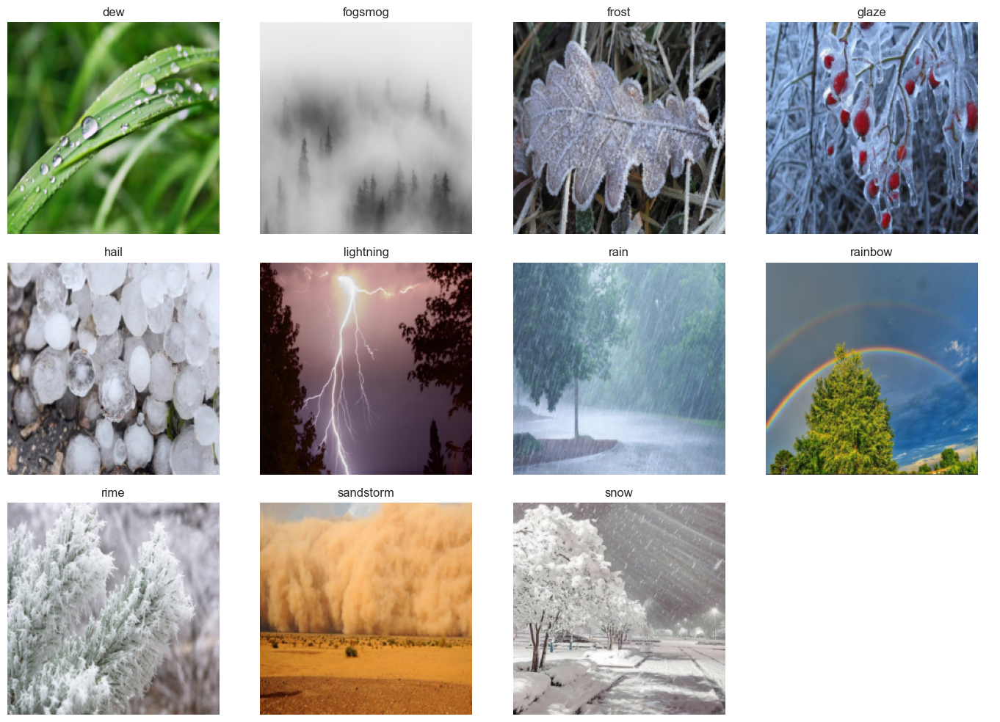

In [4]:
plot_image_samples(dataset=photos_dataset, indices_dict=photos_indices)

## Аугментированные изображения

In [5]:
if not os.listdir(os.path.join(aug_path, class_names[0])):
    for class_name in class_names:
        source_dir = os.path.join(data_path, class_name)
        target_dir = os.path.join(aug_path, class_name)

        image_paths = [image_path for image_path in os.listdir(source_dir)]

        for image_path in random.sample(image_paths, k=n_images_per_class):
            shutil.copy(
                os.path.join(source_dir, image_path),
                os.path.join(target_dir, image_path)
            )

aug_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=30),
    transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4, hue=0.1),
    transforms.RandomResizedCrop(size=image_size, scale=(0.7, 1.0)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])

aug_dataset_path = f"{test_path}/weather_aug.pt"

if not os.path.exists(aug_dataset_path):
    raw_aug_dataset = ImageFolder(aug_path, transform=aug_transform)

    aug_tensors_list = []
    aug_targets_list = []

    for image_index in range(len(raw_aug_dataset)):
        image_tensor, target = raw_aug_dataset[image_index]
        aug_tensors_list.append(image_tensor)
        aug_targets_list.append(target)
        
    aug_images_tensor = torch.stack(aug_tensors_list)
    aug_targets_tensor = torch.tensor(aug_targets_list)

    torch.save((aug_images_tensor, aug_targets_tensor), aug_dataset_path)

else:
    aug_images_tensor, aug_targets_tensor = torch.load(aug_dataset_path)

aug_dataset = TensorDataset(aug_images_tensor, aug_targets_tensor)
aug_loader = DataLoader(aug_dataset, batch_size=batch_size, shuffle=False)

aug_targets = aug_targets_tensor.tolist()
aug_counts = {class_names[target]: cnt for target, cnt in Counter(aug_targets).items()}

aug_indices = defaultdict(list)
for image_index, target in enumerate(aug_targets):
    aug_indices[class_names[target]].append(image_index)

print("Количество аугментированных изображений каждого класса:")
for class_name, cnt in aug_counts.items():
    print(f"'{class_name}': {cnt}")

Количество аугментированных изображений каждого класса:
'dew': 12
'fogsmog': 12
'frost': 12
'glaze': 12
'hail': 12
'lightning': 12
'rain': 12
'rainbow': 12
'rime': 12
'sandstorm': 12
'snow': 12


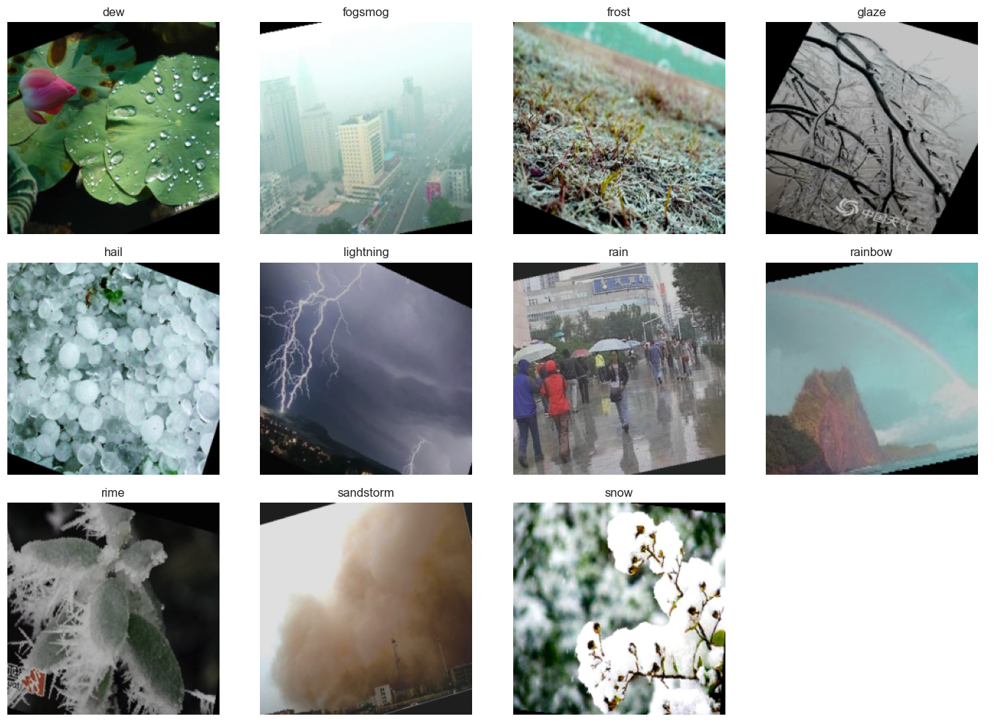

In [6]:
plot_image_samples(dataset=aug_dataset, indices_dict=aug_indices)

## Stable Diffusion

In [7]:
diffusion_pipe = StableDiffusionPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    torch_dtype=torch.float16 if current_device.type == "cuda" else torch.float32,
    safety_checker=None,
    feature_extractor=None,
)
diffusion_pipe = diffusion_pipe.to(current_device)
diffusion_pipe.set_progress_bar_config(disable=True)

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


In [ ]:
prompts = {
    "dew": [
        "macro of transparent dew drops on bright green grass blade, morning sunlight, bokeh background, photorealistic, high resolution",
        "close-up of dew drops on flower petals, spherical water droplets, natural light, macro nature photography"
    ],
    "fogsmog": [
        "dense white fog in a pine forest, trees fading into mist, atmospheric, high resolution, photorealistic",
        "urban smog on a city street, yellowish-brown haze, cars with headlights on, low visibility, realistic photo"
    ],
    "frost": [
        "macro of tiny plant covered in delicate frost crystals, icy dust on green surface, sharp detail, natural morning light, photorealistic",
        "frost-covered grass field at sunrise, white icy coating, landscape, photorealistic"
    ],
    "glaze": [
        "clear ice glaze covering tree branches, glossy glass-like surface, dark background, macro shot",
        "glaze ice on bush twigs after freezing rain, transparent coating, detailed photo, high resolution"
    ],
    "hail": [
        "hailstones of various sizes scattered on green grass, some melting, close-up, natural light",
        "a person's open hand holding several hailstones, some spherical some irregular some melting, close-up, visible fingers, natural daylight, photorealistic"
    ],
    "lightning": [
        "forked lightning bolt illuminating a night sky over a lake, no rain, dramatic clouds, photorealistic",
        "lightning strike over a city skyline at night, dark storm clouds, high resolution, real sky phenomenon"
    ],
    "rain": [
        "heavy rain falling on a city street, wet pavement reflections, people with umbrellas, cinematic mood, photorealistic",
        "rain against a window pane, green trees outside, shallow depth of field, melancholy atmosphere, realistic"
    ],
    "rainbow": [
        "bright rainbow arc over green hills after rainfall, blue sky, vivid colors, landscape photography",
        "rainbow near a waterfall, misty air, spectral colors, nature photo, high resolution"
    ],
    "rime": [
        "rime ice buildup on pine branches, opaque white and grainy texture, winter forest, soft light, photorealistic",
        "distant view of a forest where every tree is completely coated in thick white rime ice, clear blue sky, sharp visible branches, sunny winter day, high resolution, landscape photography"
    ],
    "sandstorm": [
        "massive sandstorm cloud approaching a desert town, orange-brown sky, dramatic, photorealistic",
        "sandstorm in an open desert, reduced visibility, dunes partially obscured, realistic weather photo"
    ],
    "snow": [
        "fresh snowfall on pine trees, thick white layers, sun shining through, tranquil, high resolution",
        "urban street after heavy snow, parked cars covered, people walking, winter scene, photorealistic"
    ]
}

image_number = 133
start_time = time()

for class_name in class_names:
    prompt1, prompt2 = prompts[class_name]

    for i in range(n_images_per_class):
        if i < 6:
            prompt = prompt1
        else:
            prompt = prompt2
        
        gen_start_time = time()
        
        with torch.no_grad():
            image = diffusion_pipe(
                prompt=prompt,
                height=512,
                width=512,
                num_inference_steps=25,
                guidance_scale=7.5
            ).images[0]
        
        gen_end_time = time()
        gen_time = round(gen_end_time - gen_start_time)
        
        image_path = os.path.join(diffusion_path, class_name, f"{image_number}.jpg").replace("\\", "/")
        image.save(image_path)
        print(f"Сгенерировано изображение '{image_path}' ({gen_time}s)")

        image_number += 1
    
    print()

end_time = time()
elapsed_time = str(timedelta(seconds=round(end_time - start_time)))
print(f"Сгенерировано {n_classes * n_images_per_class} изображений за {elapsed_time} секунд")

Сгенерировано изображение './test/diffusion/dew/133.jpg' (138s)
Сгенерировано изображение './test/diffusion/dew/134.jpg' (155s)
Сгенерировано изображение './test/diffusion/dew/135.jpg' (146s)
Сгенерировано изображение './test/diffusion/dew/136.jpg' (155s)
Сгенерировано изображение './test/diffusion/dew/137.jpg' (153s)
Сгенерировано изображение './test/diffusion/dew/138.jpg' (154s)
Сгенерировано изображение './test/diffusion/dew/139.jpg' (154s)
Сгенерировано изображение './test/diffusion/dew/140.jpg' (153s)
Сгенерировано изображение './test/diffusion/dew/141.jpg' (154s)
Сгенерировано изображение './test/diffusion/dew/142.jpg' (154s)
Сгенерировано изображение './test/diffusion/dew/143.jpg' (154s)
Сгенерировано изображение './test/diffusion/dew/144.jpg' (154s)

Сгенерировано изображение './test/diffusion/fogsmog/145.jpg' (155s)
Сгенерировано изображение './test/diffusion/fogsmog/146.jpg' (153s)
Сгенерировано изображение './test/diffusion/fogsmog/147.jpg' (154s)
Сгенерировано изображение '

In [9]:
diffusion_dataset = ImageFolder(diffusion_path, transform=base_transform)
diffusion_loader = DataLoader(diffusion_dataset, batch_size=batch_size, shuffle=False)

diffusion_targets = diffusion_dataset.targets
diffusion_counts = {class_names[target]: cnt for target, cnt in Counter(diffusion_targets).items()}

diffusion_indices = defaultdict(list)
for image_index, target in enumerate(diffusion_targets):
    diffusion_indices[class_names[target]].append(image_index)

print("Количество новых изображений каждого класса:")
for class_name, cnt in diffusion_counts.items():
    print(f"'{class_name}': {cnt}")

Количество новых изображений каждого класса:
'dew': 12
'fogsmog': 12
'frost': 12
'glaze': 12
'hail': 12
'lightning': 12
'rain': 12
'rainbow': 12
'rime': 12
'sandstorm': 12
'snow': 12


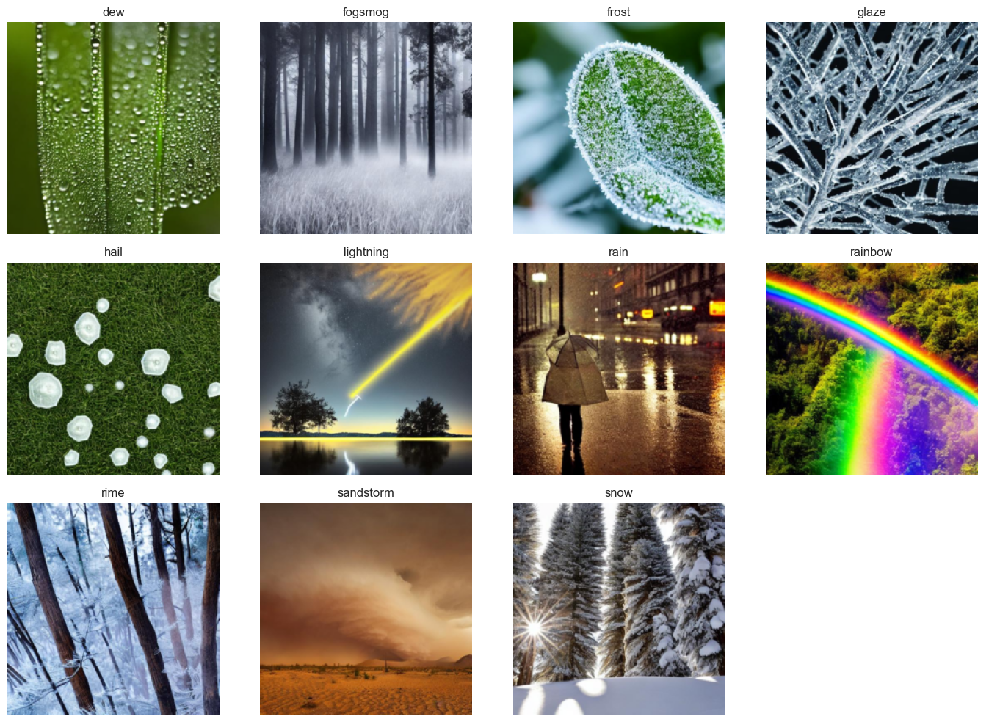

In [10]:
plot_image_samples(dataset=diffusion_dataset, indices_dict=diffusion_indices)

# Инициализация моделей

In [11]:
class WeatherMLP(nn.Module):
    def __init__(self, n_classes):
        super().__init__()

        # (batch, 3, 224, 224) -> (batch, 3, 16, 16)
        self.input_pool = nn.AdaptiveAvgPool2d((16, 16))

        self.classifier = nn.Sequential(
            nn.Flatten(),  # (batch, 3, 16, 16) -> (batch, 768)
            nn.Linear(3 * 16 * 16, 512),  # (batch, 768) -> (batch, 512)
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, 256),  # (batch, 512) -> (batch, 256)
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, n_classes)  # (batch, 256) -> (batch, n_classes)
        )

    def forward(self, x):
        x = self.input_pool(x)
        return self.classifier(x)


class WeatherCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()

        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),  # (batch, 3, 224, 224) -> (batch, 32, 224, 224)
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),  # (batch, 32, 224, 224) -> (batch, 32, 224, 224)
            nn.ReLU(),
            nn.MaxPool2d(2),  # (batch, 32, 224, 224) -> (batch, 32, 112, 112)
            nn.Dropout2d(0.2),
        )

        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),  # (batch, 32, 112, 112) -> (batch, 64, 112, 112)
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),  # (batch, 64, 112, 112) -> (batch, 64, 112, 112)
            nn.ReLU(),
            nn.MaxPool2d(2),  # (batch, 64, 112, 112) -> (batch, 64, 56, 56)
            nn.Dropout2d(0.3),
        )

        self.conv_block_3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),  # (batch, 64, 56, 56) -> (batch, 128, 56, 56)
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),  # (batch, 128, 56, 56) -> (batch, 128, 56, 56)
            nn.ReLU(),
            nn.MaxPool2d(2),  # (batch, 128, 56, 56) -> (batch, 128, 28, 28)
            nn.Dropout2d(0.4),
        )

        self.conv_block_4 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1),  # (batch, 128, 28, 28) -> (batch, 256, 28, 28)
            nn.ReLU(),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),  # (batch, 256, 28, 28) -> (batch, 256, 28, 28)
            nn.ReLU(),
            nn.MaxPool2d(2),  # (batch, 256, 28, 28) -> (batch, 256, 14, 14)
            nn.Dropout2d(0.4),
        )

        # (batch, 256, 14, 14) -> (batch, 256, 4, 4)
        self.global_pool = nn.AdaptiveAvgPool2d((4, 4))

        self.classifier = nn.Sequential(
            nn.Flatten(),  # (batch, 256, 4, 4) -> (batch, 4096)
            nn.Linear(256 * 4 * 4, 256),  # (batch, 4096) -> (batch, 256)
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, n_classes),  # (batch, 256) -> (batch, n_classes)
        )

    def forward(self, x):
        x = self.conv_block_1(x)
        x = self.conv_block_2(x)
        x = self.conv_block_3(x)
        x = self.conv_block_4(x)
        x = self.global_pool(x)
        return self.classifier(x)


resnet18 = models.resnet18()
resnet18.fc = nn.Linear(resnet18.fc.in_features, n_classes)

mobilenet_v3_large = models.mobilenet_v3_large()
mobilenet_v3_large.classifier[3] = nn.Linear(mobilenet_v3_large.classifier[3].in_features, n_classes)

efficientnet_b0 = models.efficientnet_b0()
efficientnet_b0.classifier[1] = nn.Linear(efficientnet_b0.classifier[1].in_features, n_classes)

models_dict = {
    "WeatherMLP": WeatherMLP(n_classes=n_classes),
    "WeatherCNN": WeatherCNN(n_classes=n_classes),
    "ResNet18": resnet18,
    "MobileNetV3-Large": mobilenet_v3_large,
    "EfficientNet-B0": efficientnet_b0,
}

models_short = {
    "WeatherMLP": "MLP",
    "WeatherCNN": "CNN",
    "ResNet18": "ResNet",
    "MobileNetV3-Large": "MobNet",
    "EfficientNet-B0": "EffNet",
}

for model_name, model in models_dict.items():
    model = model.to(current_device)
    model.load_state_dict(
        torch.load(f"./models/{model_name}.pt", map_location=current_device)
    )
    params = sum(p.numel() for p in model.parameters())
    print(f"{model_name}: {params} параметров")

WeatherMLP: 527883 параметров
WeatherCNN: 2223915 параметров
ResNet18: 11182155 параметров
MobileNetV3-Large: 4216123 параметров
EfficientNet-B0: 4021639 параметров


# Тестирование моделей на новых данных

In [12]:
def evaluate_predict(model, loader, device):
    model.eval()

    correct, total = 0, 0
    all_preds, all_probs = [], []

    with torch.no_grad():
        for inputs, targets in loader:
            inputs, targets = inputs.to(device), targets.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            probs = torch.softmax(outputs, dim=1)

            correct += (preds == targets).sum().item()
            total += targets.size(0)

            all_preds.append(preds.cpu())
            all_probs.append(probs.cpu())
    
    return correct / total, torch.cat(all_preds).numpy(), torch.cat(all_probs).numpy()


def get_models_preds(models_dict, targets, loader):
    all_preds = []

    for model_name, model in models_dict.items():
        acc, preds, probs = evaluate_predict(model, loader, current_device)
        cm = confusion_matrix(targets, preds)

        all_preds.append({
            "model": model_name,
            "acc": acc,
            "preds": preds,
            "probs": probs,
            "cm": cm,
        })
    
    return all_preds


def get_models_results(all_preds, targets, dataset_size):
    results = []

    for preds in all_preds:
        correct = (preds["preds"] == targets).sum().item()

        results.append({
            "Модель": preds["model"],
            "Точность": f"{preds["acc"]:.4f}",
            "Ошибок": dataset_size - correct,
        })
    
    return results


def plot_models_confusion_matrices(all_preds):
    _, axes = plt.subplots(nrows=2, ncols=3, figsize=(14, 10))
    axes = axes.flatten()

    for i, preds in enumerate(all_preds[2:] + all_preds[:2]):
        sns.heatmap(
            preds["cm"], cmap="Greens", annot=True, fmt="d", cbar=False, square=True, ax=axes[i]
        ).set(
            xlabel="Предсказанный класс", ylabel="Истинный класс",
            xticklabels=class_names, yticklabels=class_names
        )
        axes[i].set_title(preds["model"], fontsize=14)
        axes[i].tick_params(axis="x", rotation=90)
        axes[i].tick_params(axis="y", rotation=0)

    axes[-1].axis("off")

    plt.tight_layout()

## Фотографии из Интернета

In [13]:
photos_preds = get_models_preds(models_dict, targets=photos_targets, loader=photos_loader)
photos_results = get_models_results(photos_preds, targets=photos_targets, dataset_size=len(photos_dataset))
pd.DataFrame(photos_results).style.hide(axis="index")

Модель,Точность,Ошибок
WeatherMLP,0.5227,63
WeatherCNN,0.6970,40
ResNet18,0.8712,17
MobileNetV3-Large,0.8636,18
EfficientNet-B0,0.9015,13


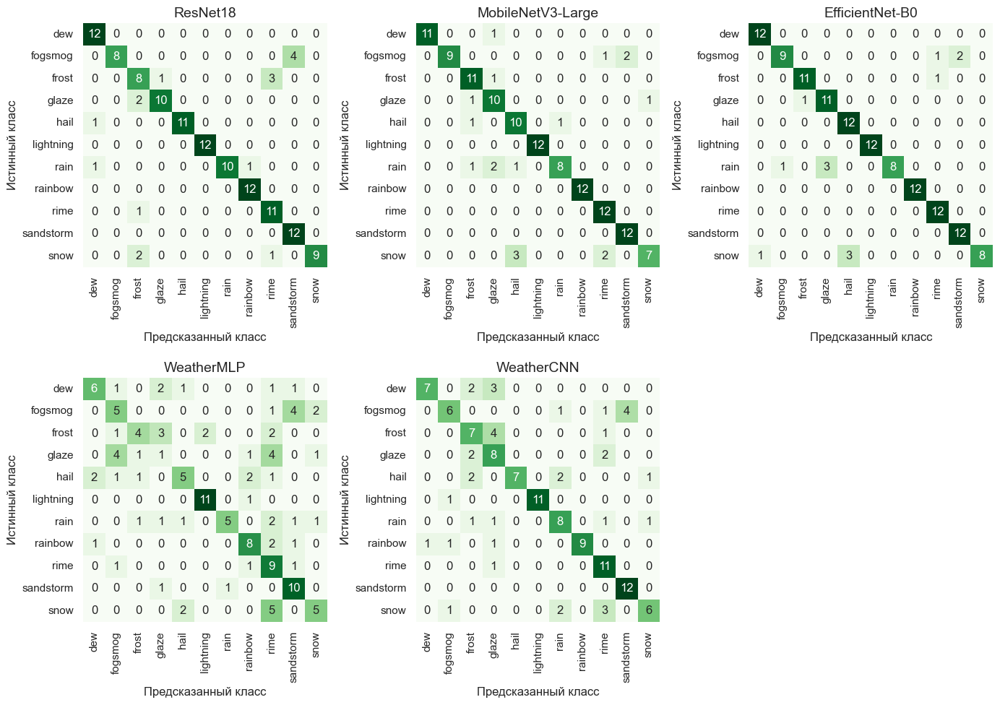

In [14]:
plot_models_confusion_matrices(photos_preds)

## Аугментированные изображения

In [15]:
aug_preds = get_models_preds(models_dict, targets=aug_targets, loader=aug_loader)
aug_results = get_models_results(aug_preds, targets=aug_targets, dataset_size=len(aug_dataset))
pd.DataFrame(aug_results).style.hide(axis="index")

Модель,Точность,Ошибок
WeatherMLP,0.4091,78
WeatherCNN,0.5303,62
ResNet18,0.8485,20
MobileNetV3-Large,0.8636,18
EfficientNet-B0,0.9091,12


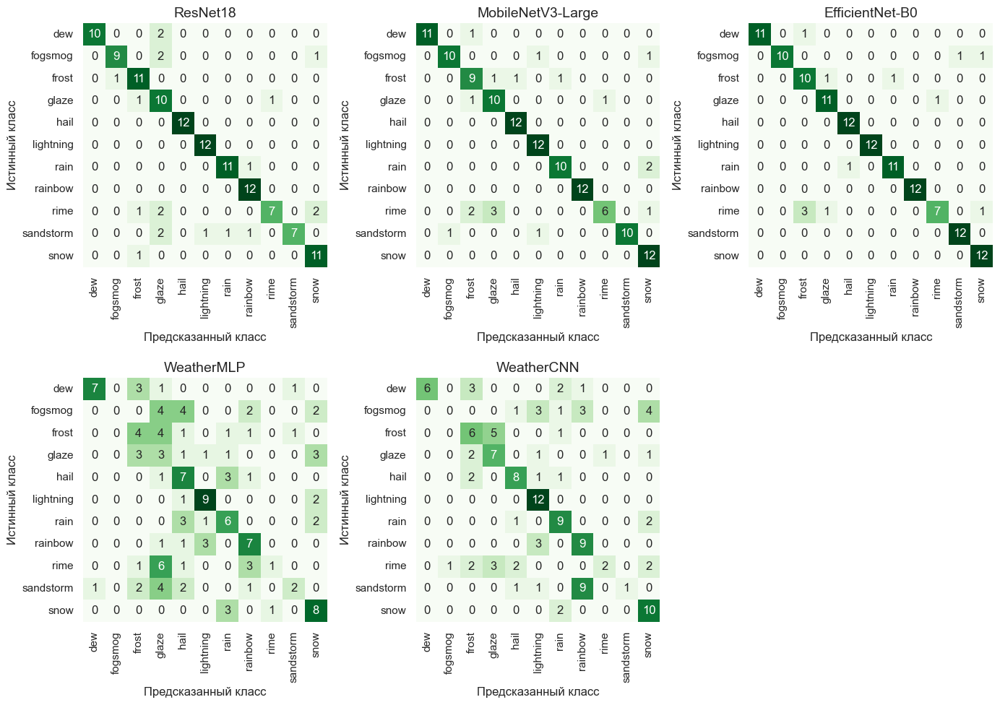

In [16]:
plot_models_confusion_matrices(aug_preds)

## Stable Diffusion

In [17]:
diffusion_preds = get_models_preds(models_dict, targets=diffusion_targets, loader=diffusion_loader)
diffusion_results = get_models_results(diffusion_preds, targets=diffusion_targets, dataset_size=len(diffusion_dataset))
pd.DataFrame(diffusion_results).style.hide(axis="index")

Модель,Точность,Ошибок
WeatherMLP,0.3712,83
WeatherCNN,0.6212,50
ResNet18,0.8182,24
MobileNetV3-Large,0.8106,25
EfficientNet-B0,0.7727,30


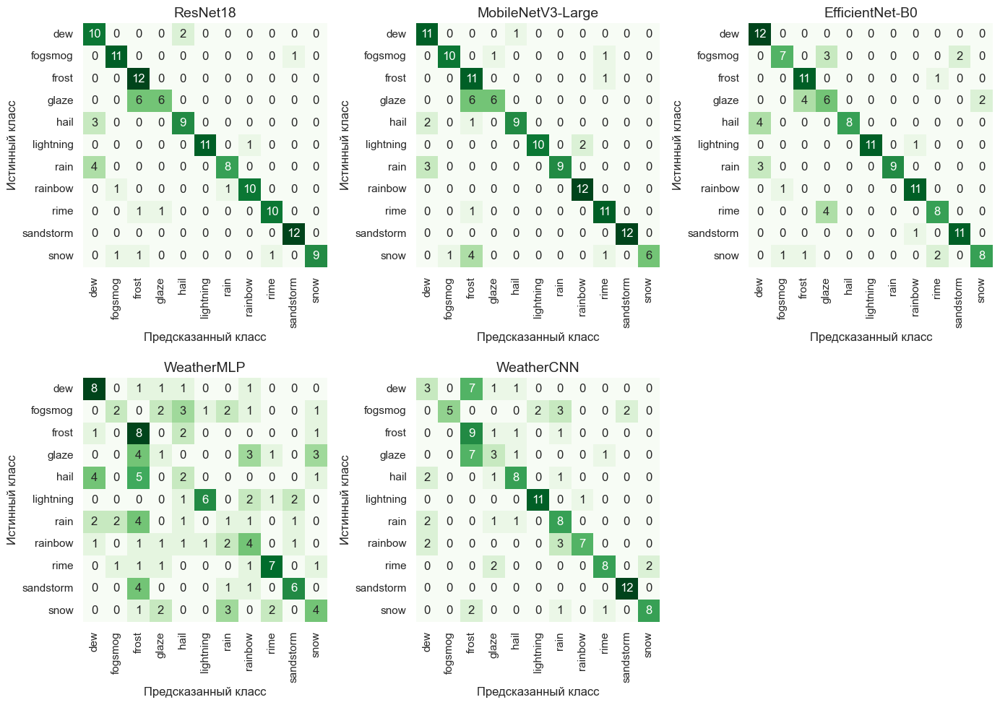

In [18]:
plot_models_confusion_matrices(diffusion_preds)

# Анализ ошибок на новых данных

In [19]:
def plot_preds(class_name, dataset, indices_dict, all_preds):
    n_models = len(all_preds)

    image_indices = indices_dict[class_name]
    n_images = len(image_indices)

    n_cols = 4
    n_rows = ceil(n_images / n_cols)

    _, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(14, n_rows * 4.5))
    axes = axes.flatten()

    for i, image_index in enumerate(image_indices):
        ax = axes[i]

        ax.imshow(get_image_array_from_tensor(dataset[image_index][0]))
        ax.axis("off")

        model_names = [models_short[preds["model"]] for preds in all_preds]
        image_preds = [preds["preds"][image_index] for preds in all_preds]
        image_probs = [preds["probs"][image_index][image_preds[j]] for j, preds in enumerate(all_preds)]

        y_step = 0.075
        y_start = 1.02 + y_step * (n_models - 1)
        for k, model_name, pred, prob in zip(range(n_models), model_names, image_preds, image_probs):
            color = "green" if class_names[pred] == class_name else "red"
            line = f"{model_name}: {class_names[pred]} ({prob:.2f})"
            ax.text(
                0.5, y_start - k * y_step, line, transform=ax.transAxes,
                ha="center", va="bottom", color=color
            )

    for i in range(n_images, len(axes)):
        axes[i].axis("off")

    plt.subplots_adjust(wspace=0.1, hspace=0.2)

## Фотографии из Интернета

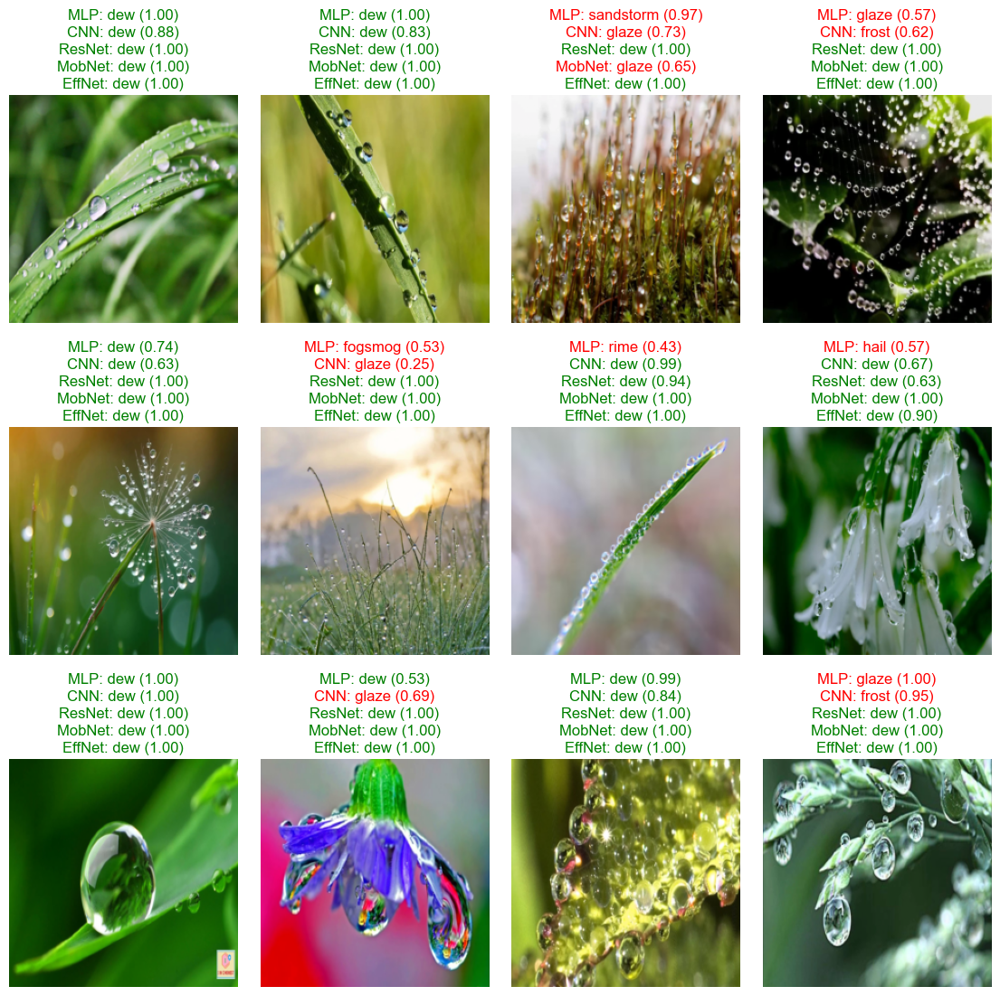

In [20]:
plot_preds("dew", dataset=photos_dataset, indices_dict=photos_indices, all_preds=photos_preds)

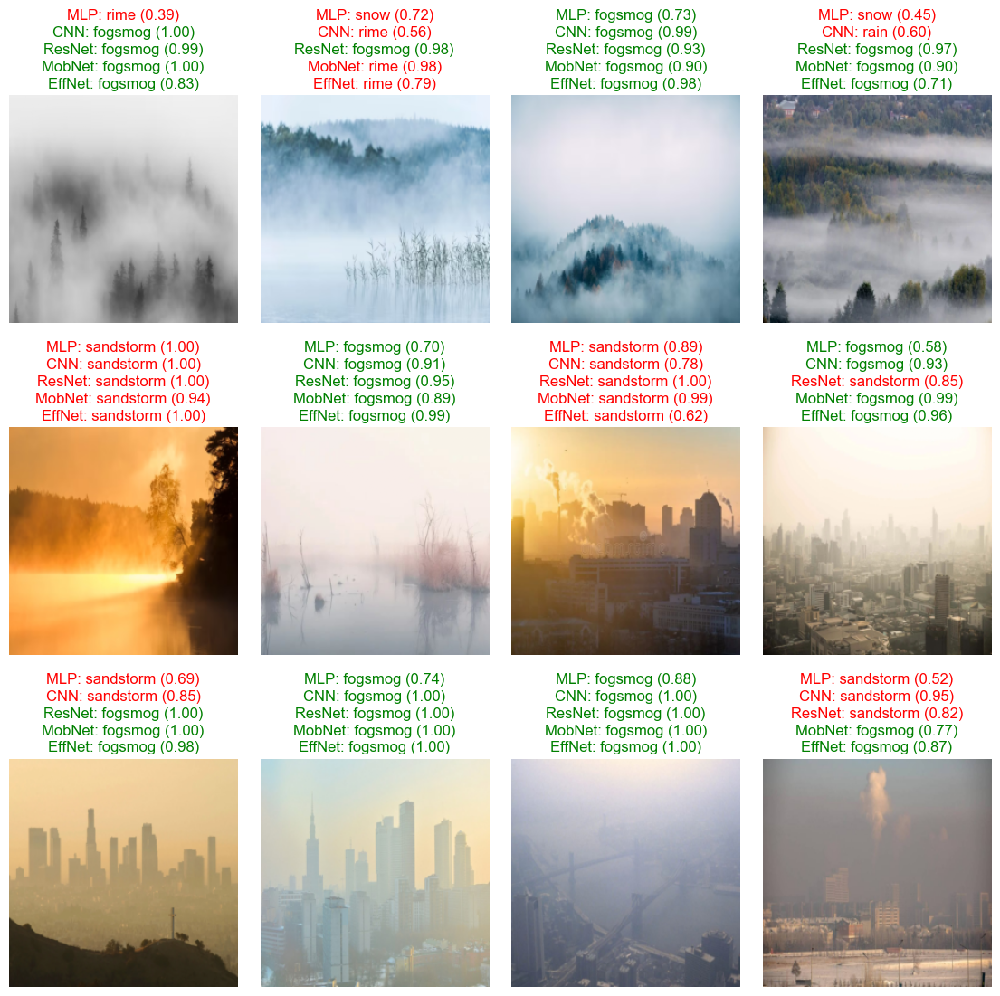

In [21]:
plot_preds("fogsmog", dataset=photos_dataset, indices_dict=photos_indices, all_preds=photos_preds)

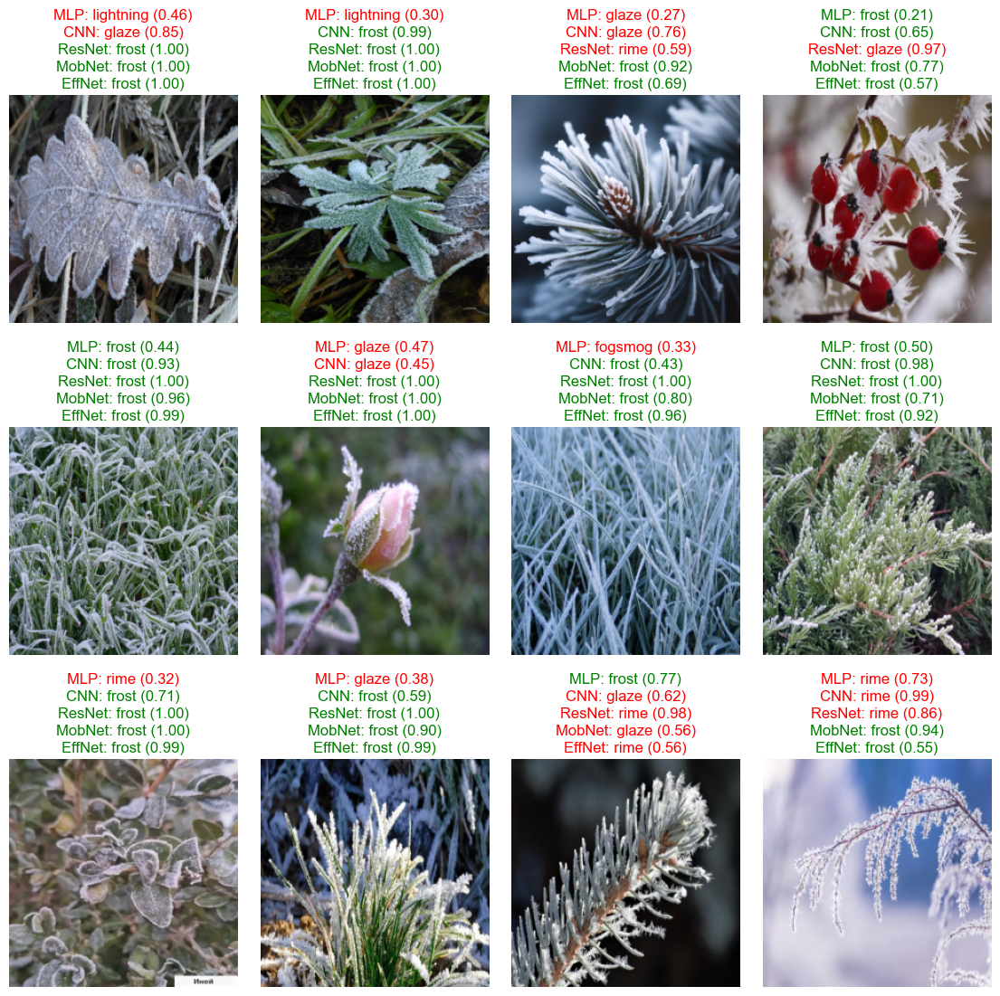

In [22]:
plot_preds("frost", dataset=photos_dataset, indices_dict=photos_indices, all_preds=photos_preds)

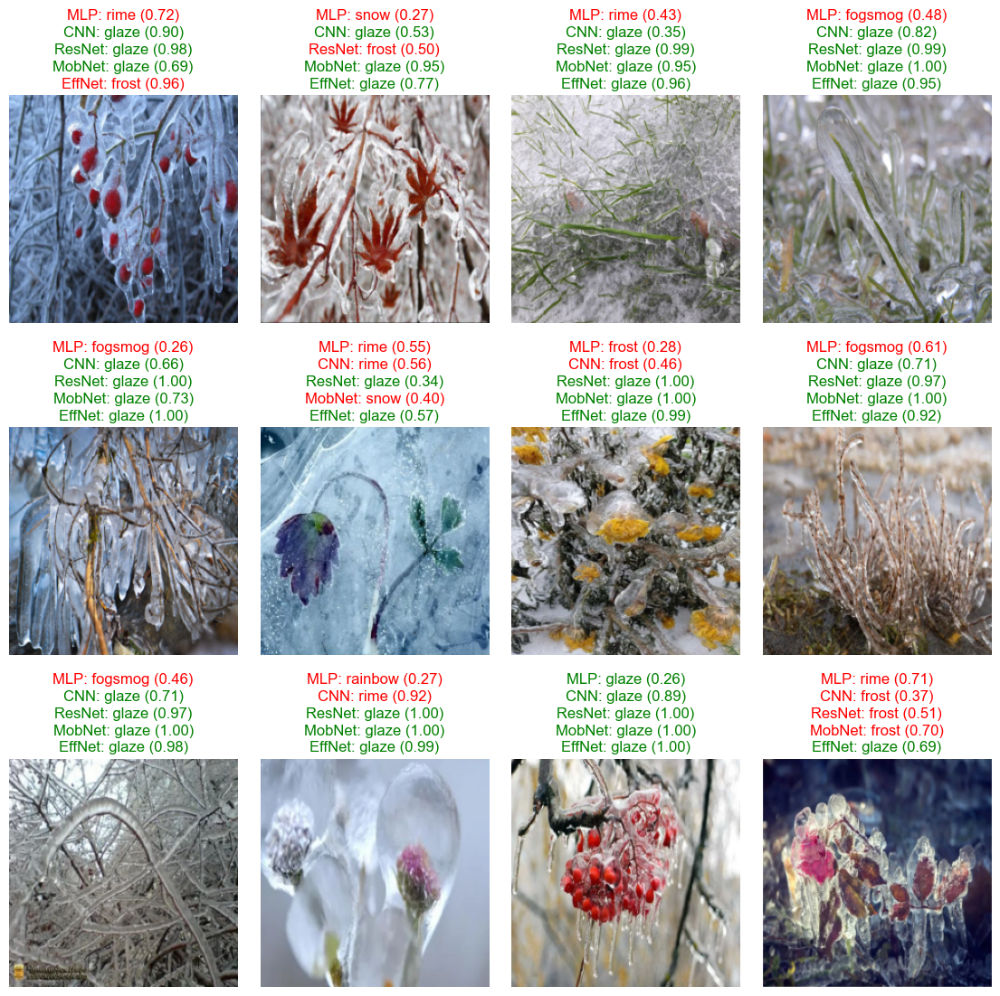

In [23]:
plot_preds("glaze", dataset=photos_dataset, indices_dict=photos_indices, all_preds=photos_preds)

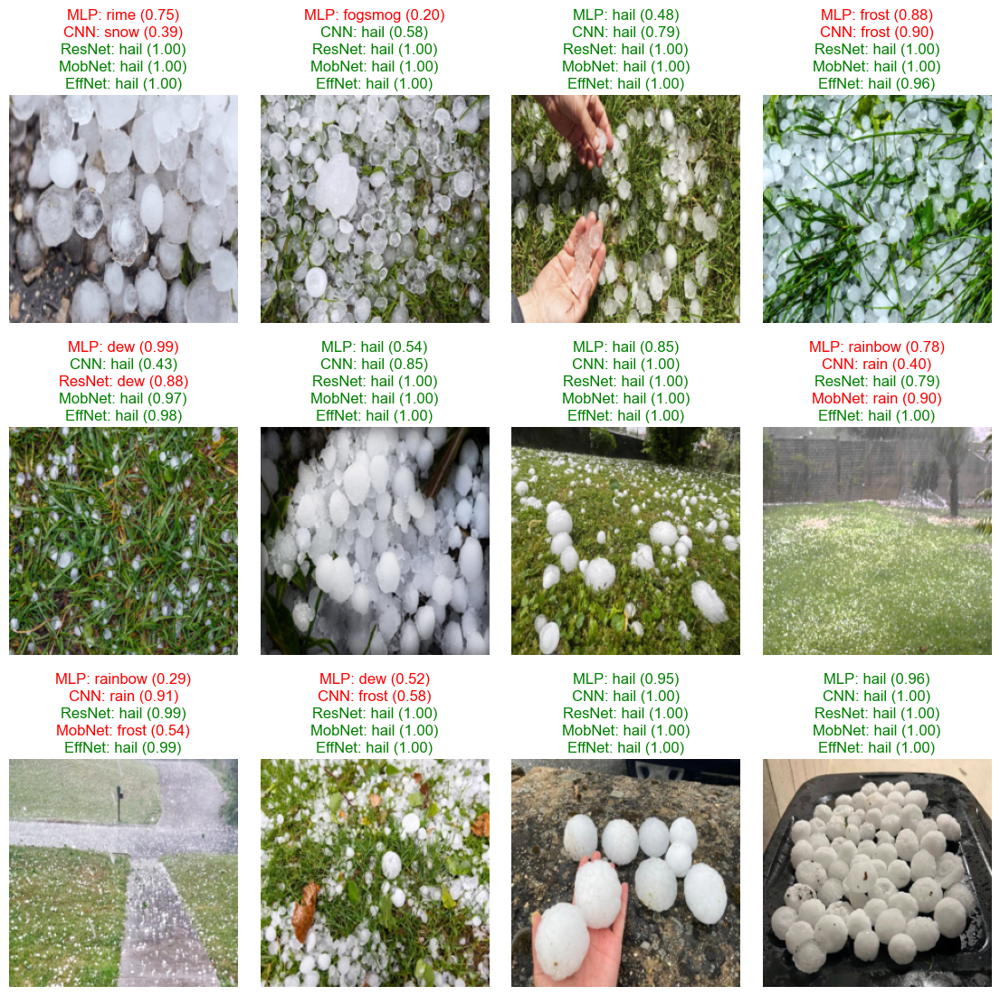

In [24]:
plot_preds("hail", dataset=photos_dataset, indices_dict=photos_indices, all_preds=photos_preds)

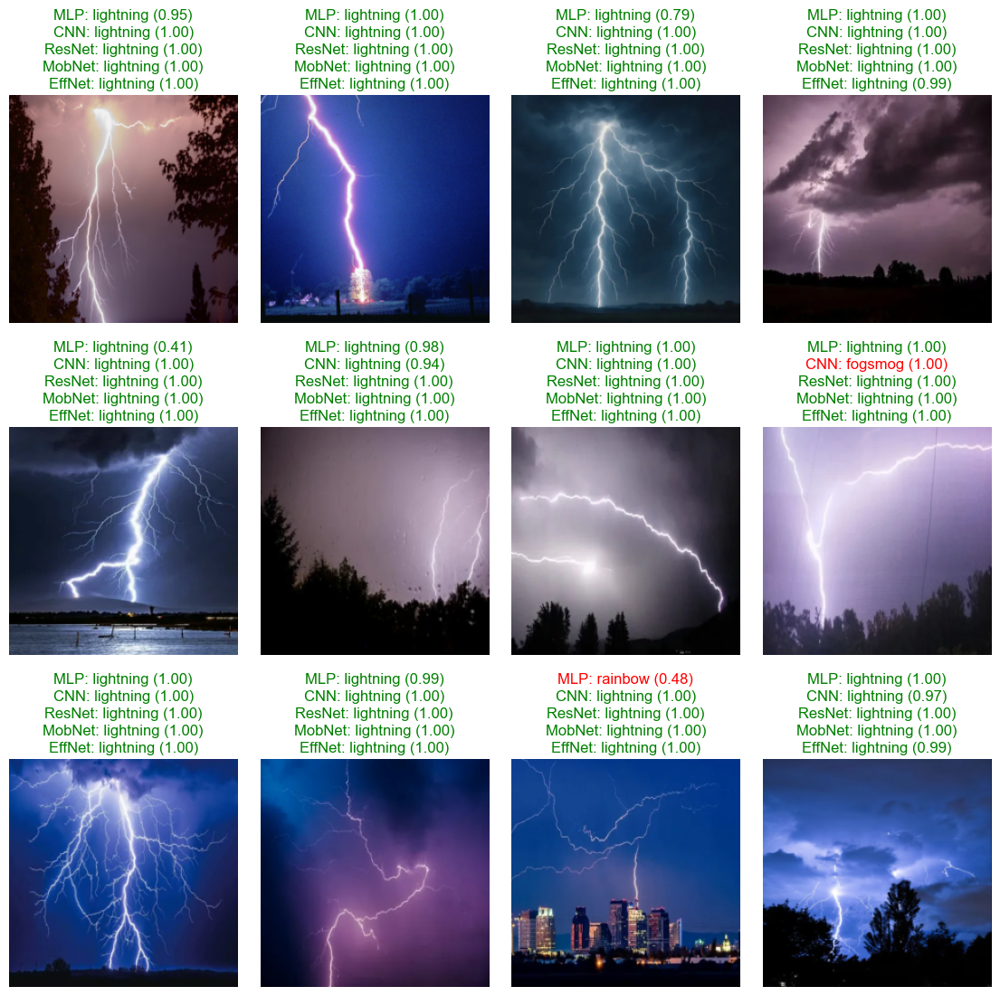

In [25]:
plot_preds("lightning", dataset=photos_dataset, indices_dict=photos_indices, all_preds=photos_preds)

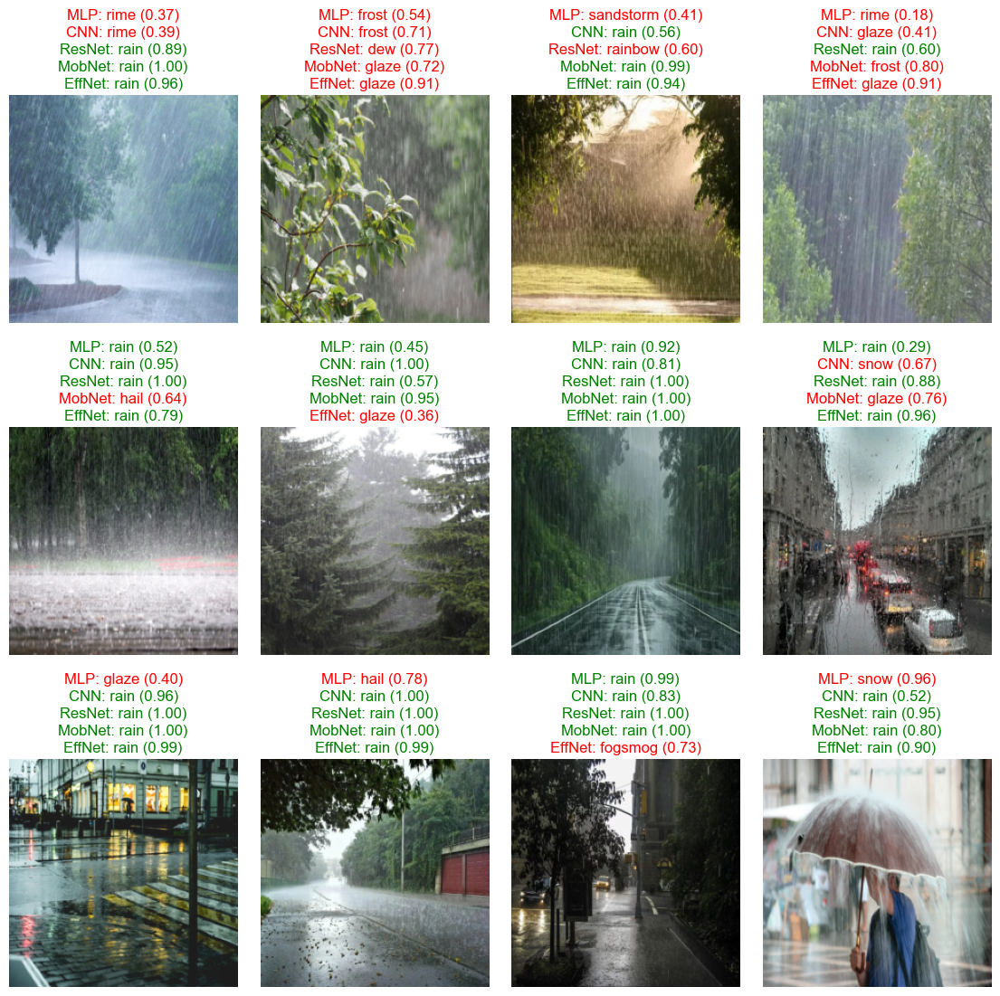

In [26]:
plot_preds("rain", dataset=photos_dataset, indices_dict=photos_indices, all_preds=photos_preds)

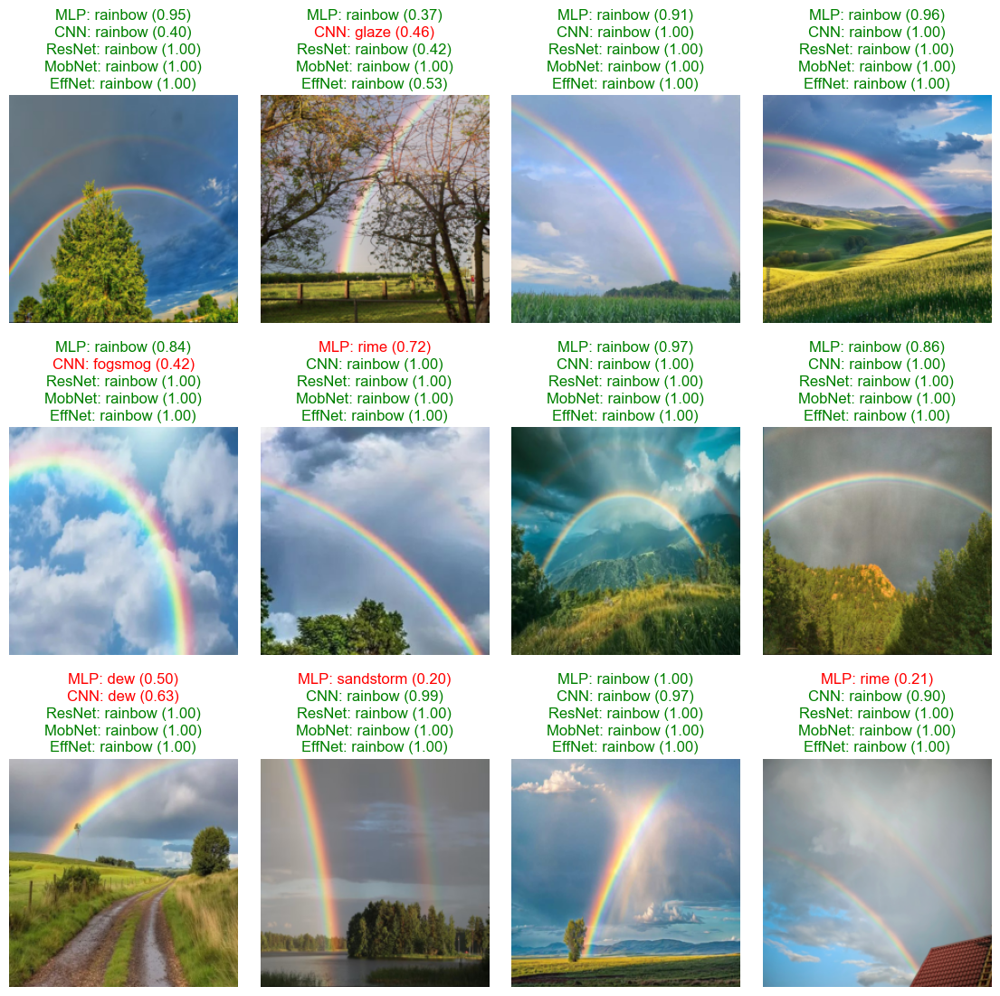

In [27]:
plot_preds("rainbow", dataset=photos_dataset, indices_dict=photos_indices, all_preds=photos_preds)

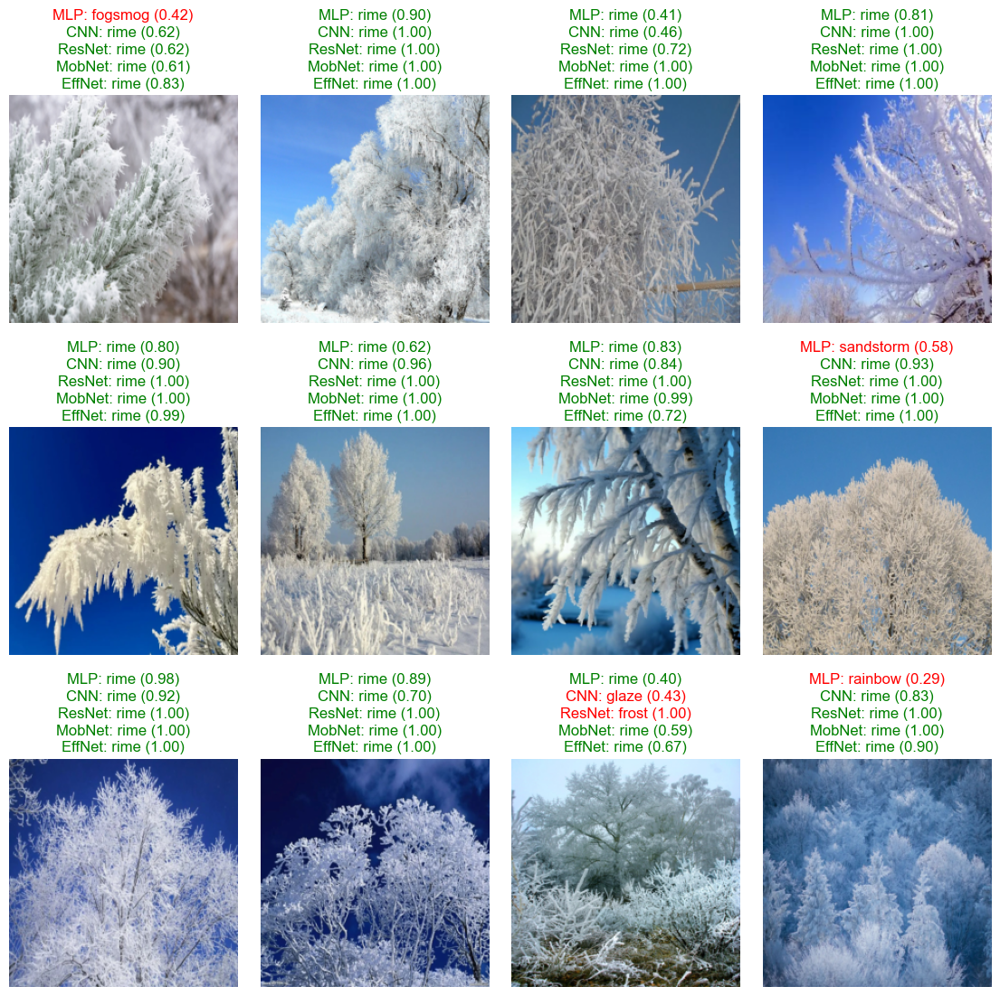

In [28]:
plot_preds("rime", dataset=photos_dataset, indices_dict=photos_indices, all_preds=photos_preds)

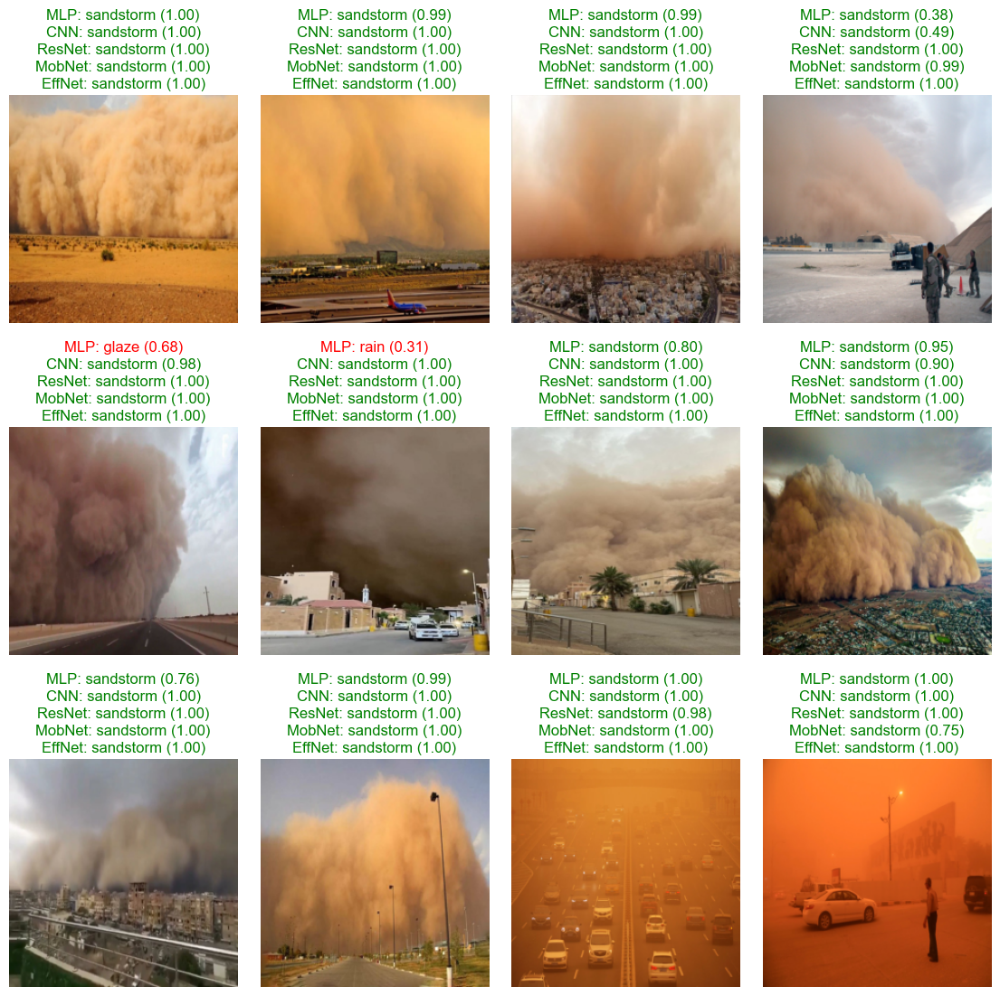

In [29]:
plot_preds("sandstorm", dataset=photos_dataset, indices_dict=photos_indices, all_preds=photos_preds)

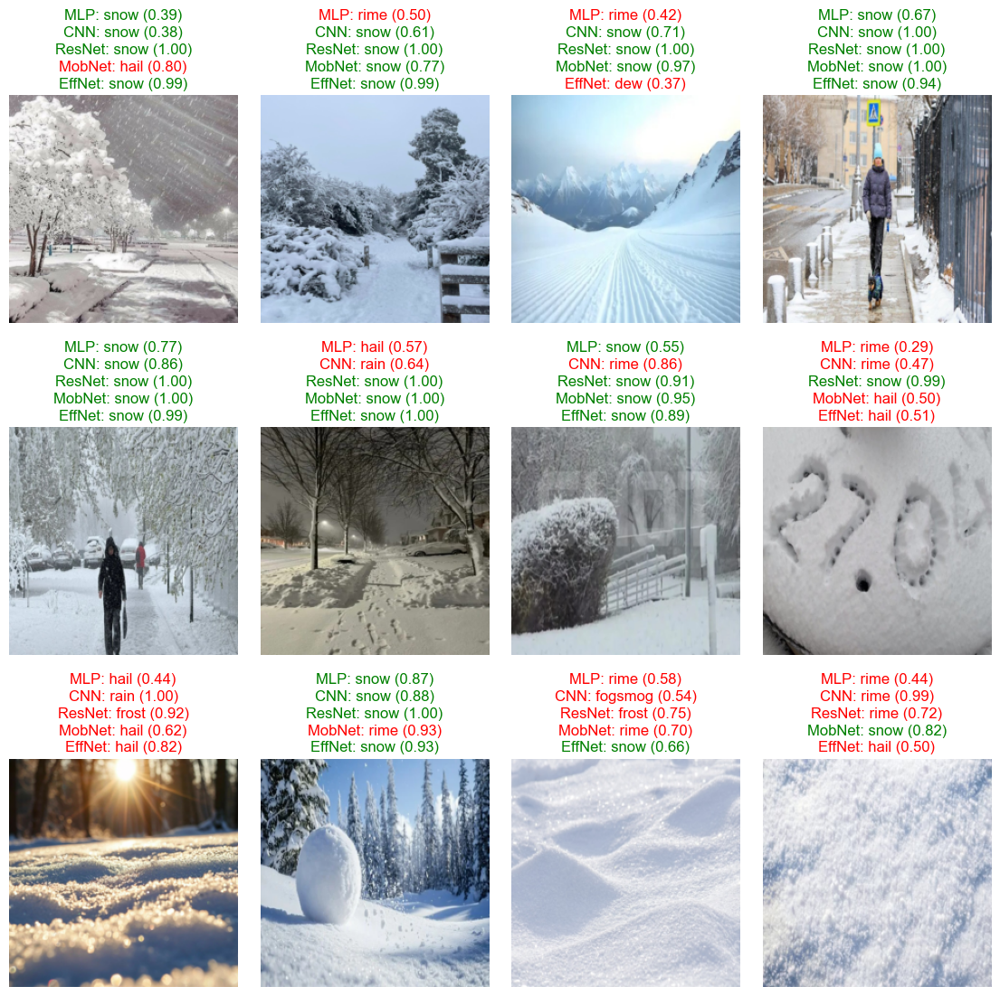

In [30]:
plot_preds("snow", dataset=photos_dataset, indices_dict=photos_indices, all_preds=photos_preds)

## Аугментированные изображения

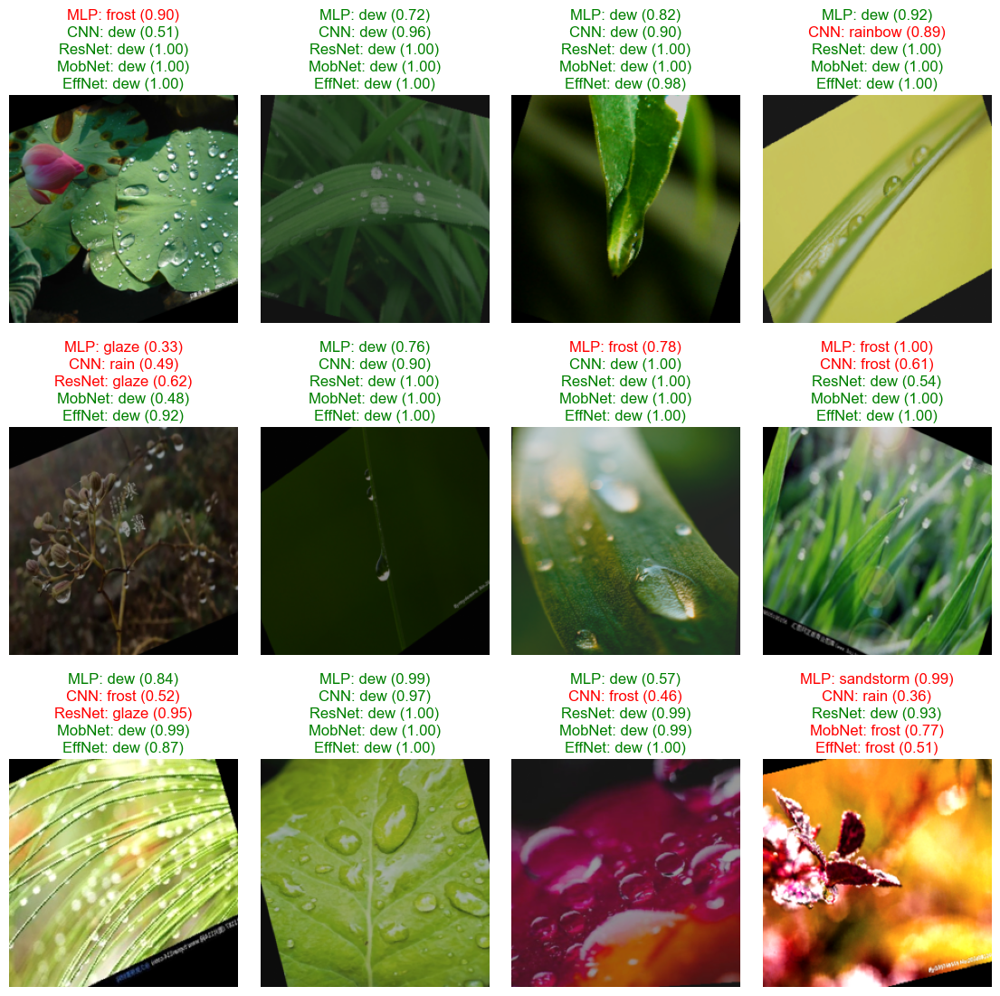

In [31]:
plot_preds("dew", dataset=aug_dataset, indices_dict=aug_indices, all_preds=aug_preds)

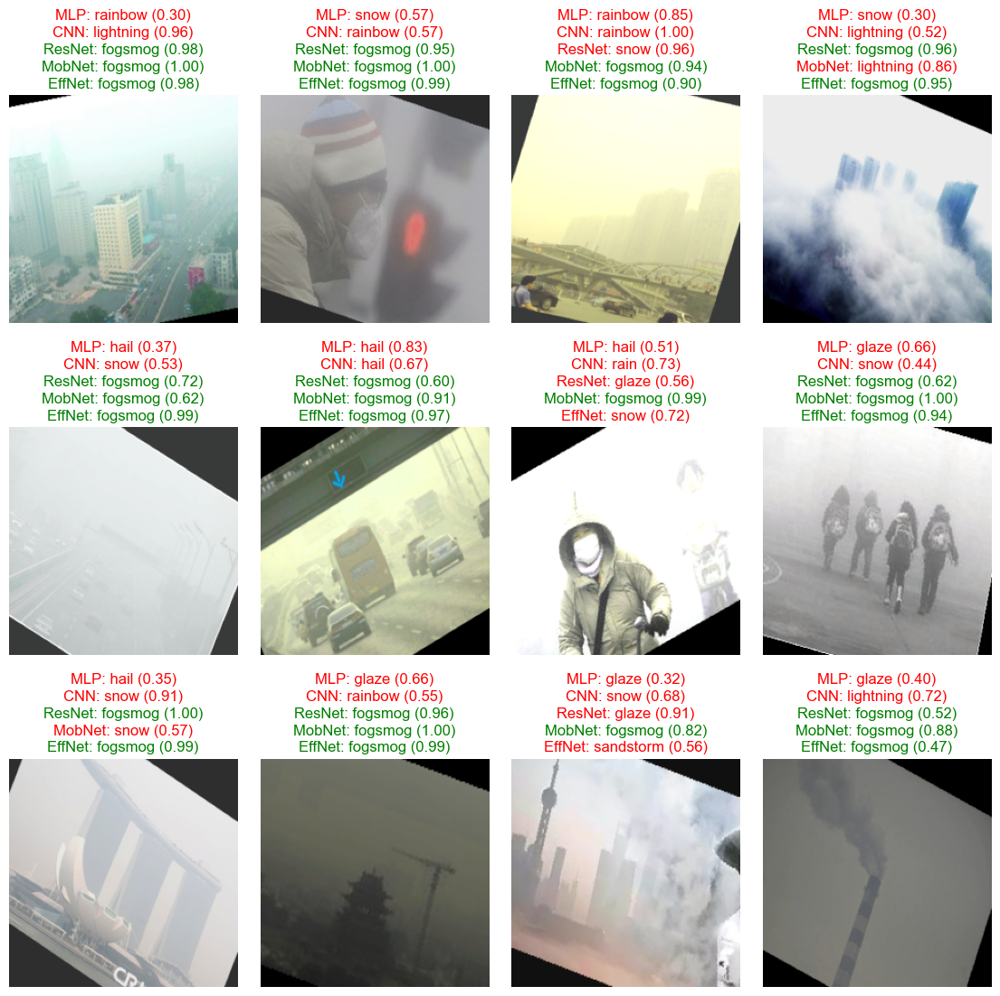

In [32]:
plot_preds("fogsmog", dataset=aug_dataset, indices_dict=aug_indices, all_preds=aug_preds)

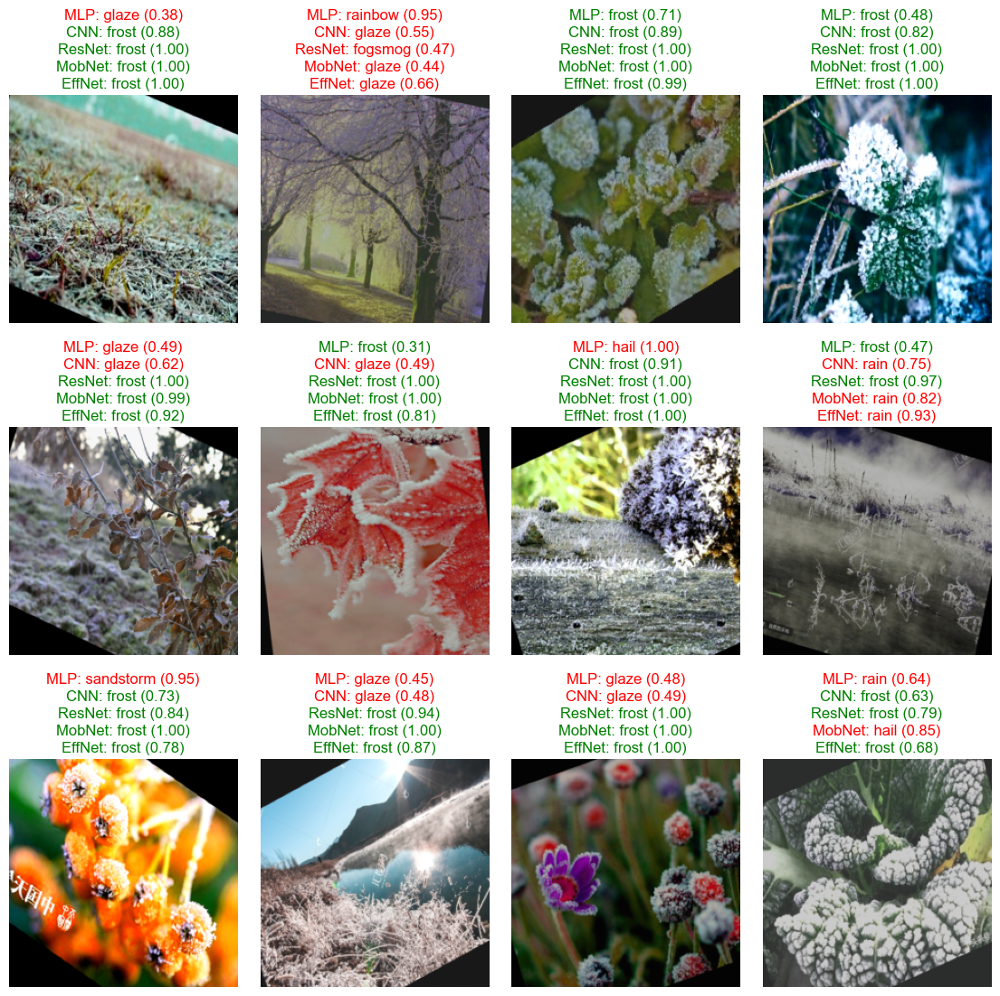

In [33]:
plot_preds("frost", dataset=aug_dataset, indices_dict=aug_indices, all_preds=aug_preds)

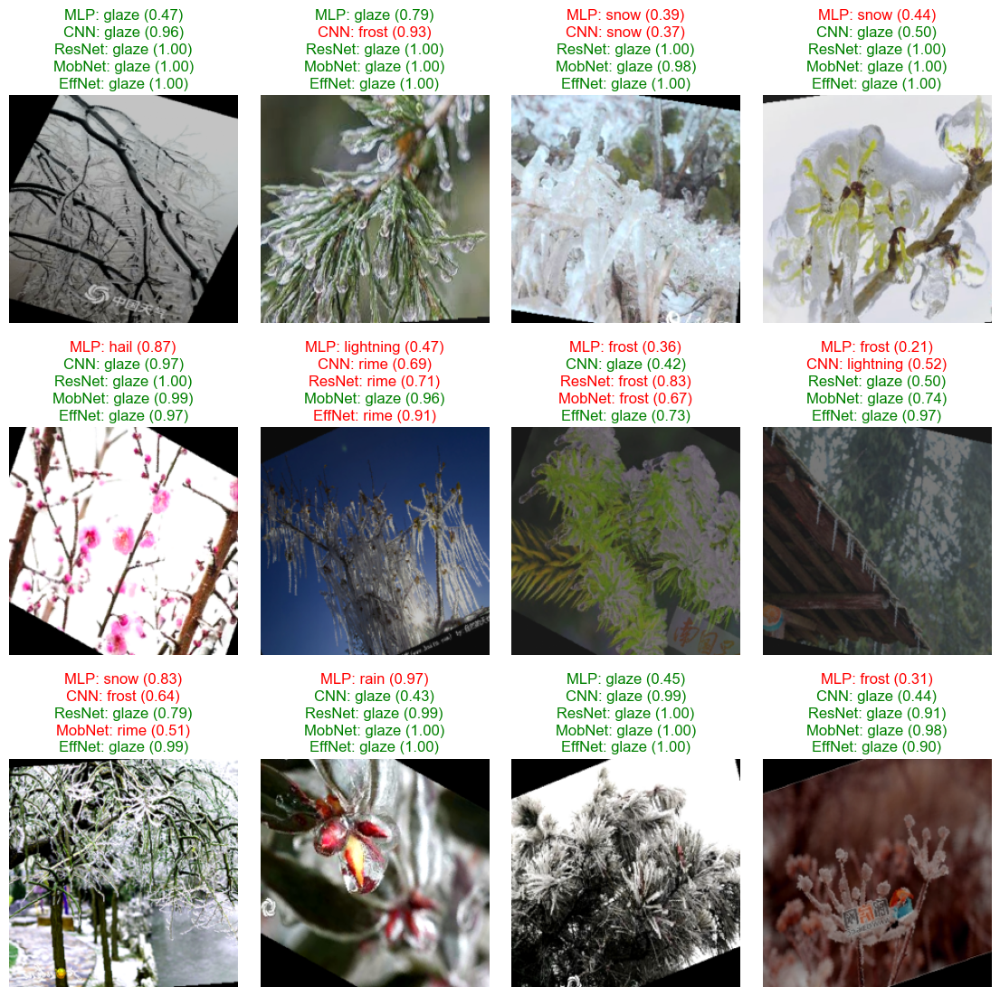

In [34]:
plot_preds("glaze", dataset=aug_dataset, indices_dict=aug_indices, all_preds=aug_preds)

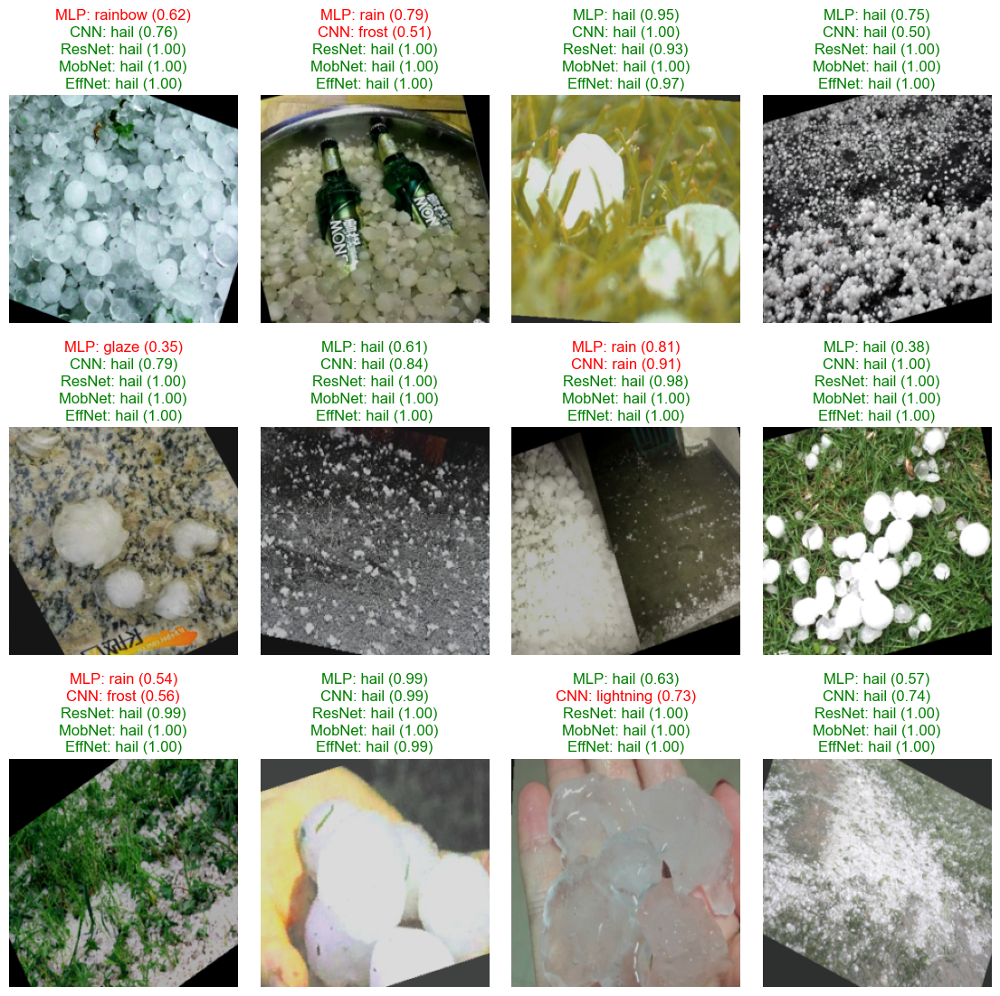

In [35]:
plot_preds("hail", dataset=aug_dataset, indices_dict=aug_indices, all_preds=aug_preds)

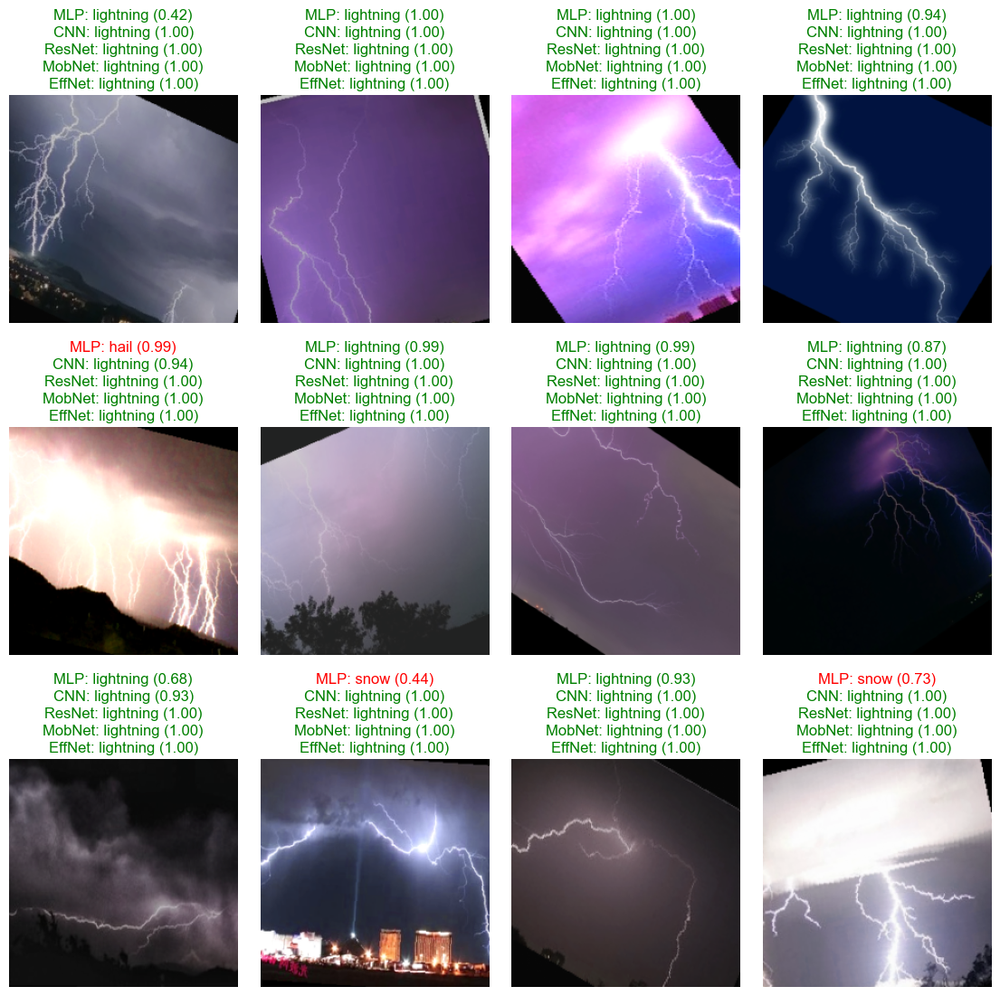

In [36]:
plot_preds("lightning", dataset=aug_dataset, indices_dict=aug_indices, all_preds=aug_preds)

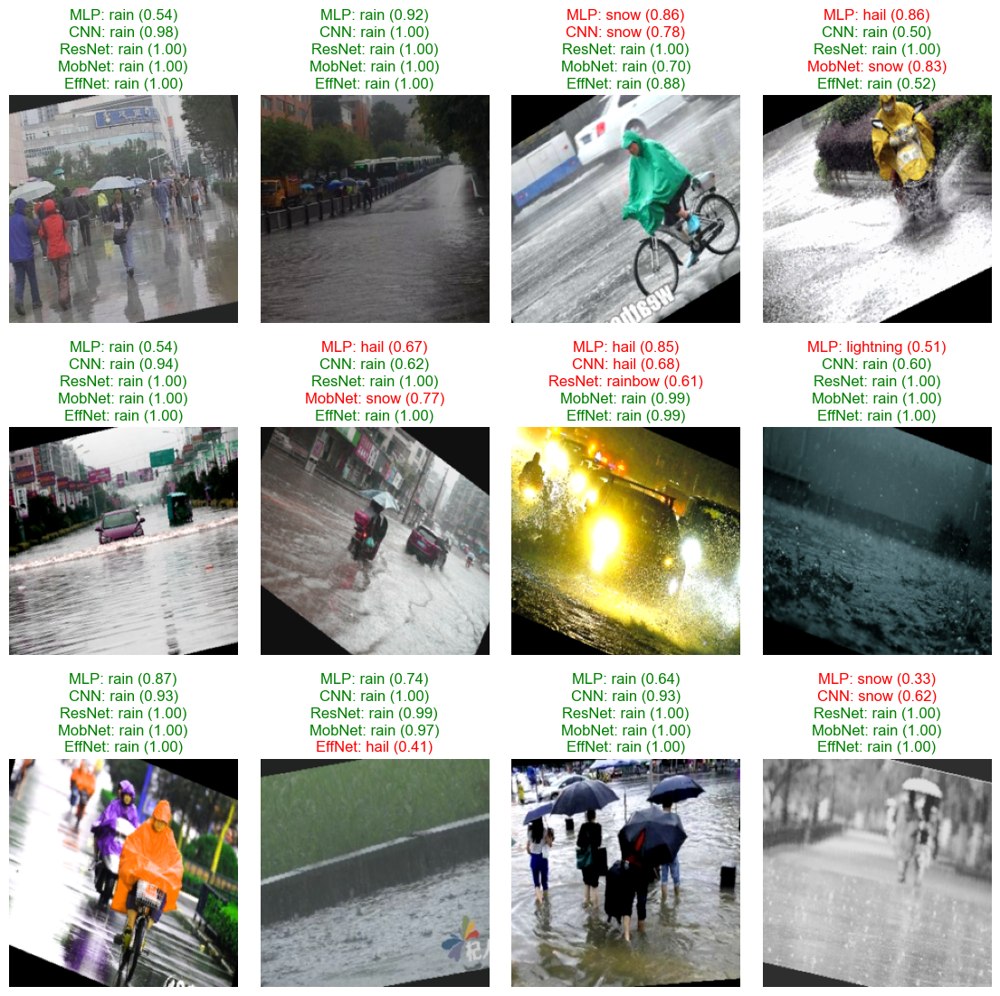

In [37]:
plot_preds("rain", dataset=aug_dataset, indices_dict=aug_indices, all_preds=aug_preds)

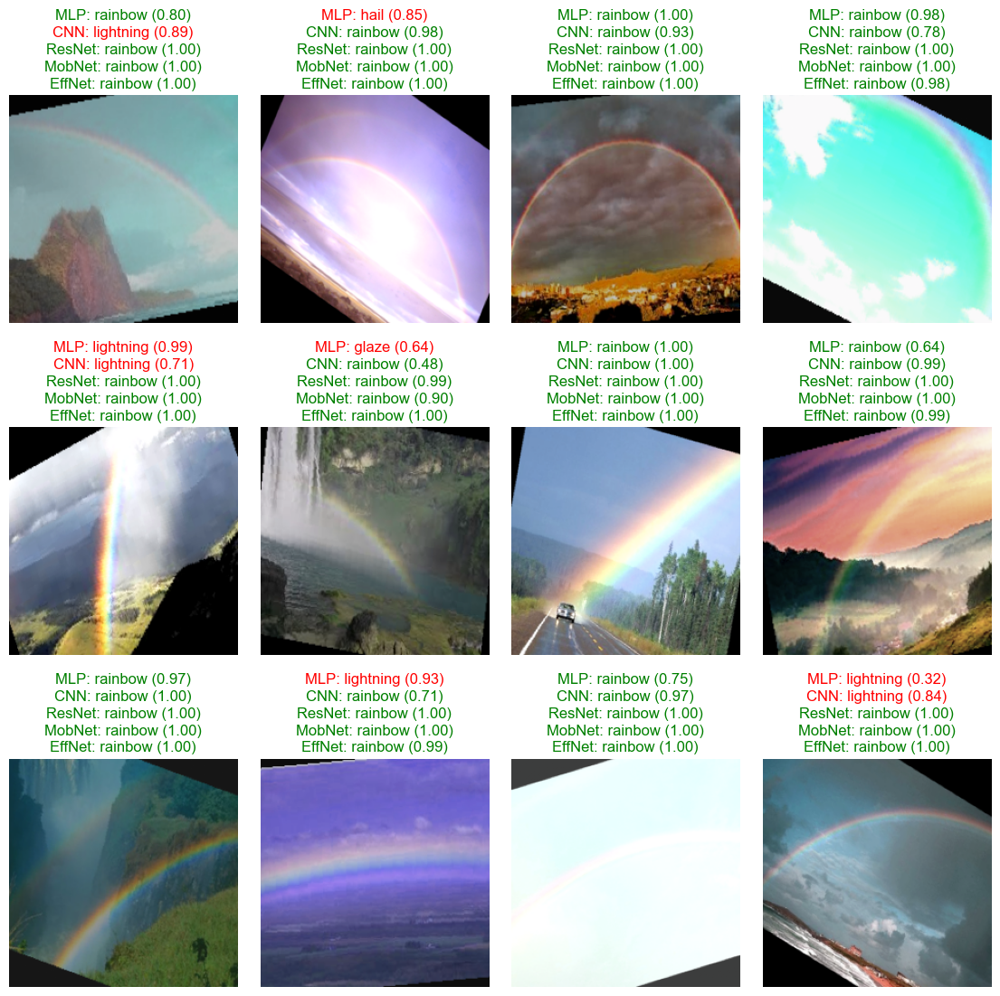

In [38]:
plot_preds("rainbow", dataset=aug_dataset, indices_dict=aug_indices, all_preds=aug_preds)

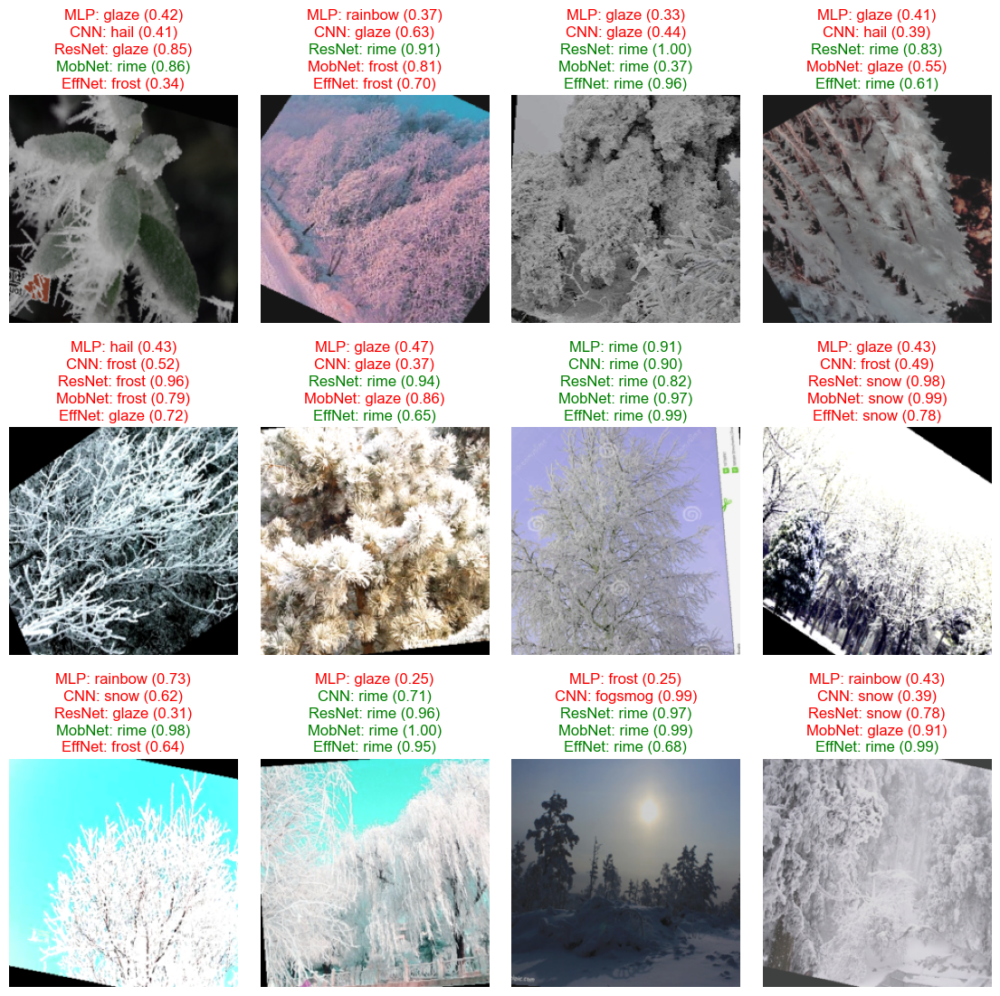

In [39]:
plot_preds("rime", dataset=aug_dataset, indices_dict=aug_indices, all_preds=aug_preds)

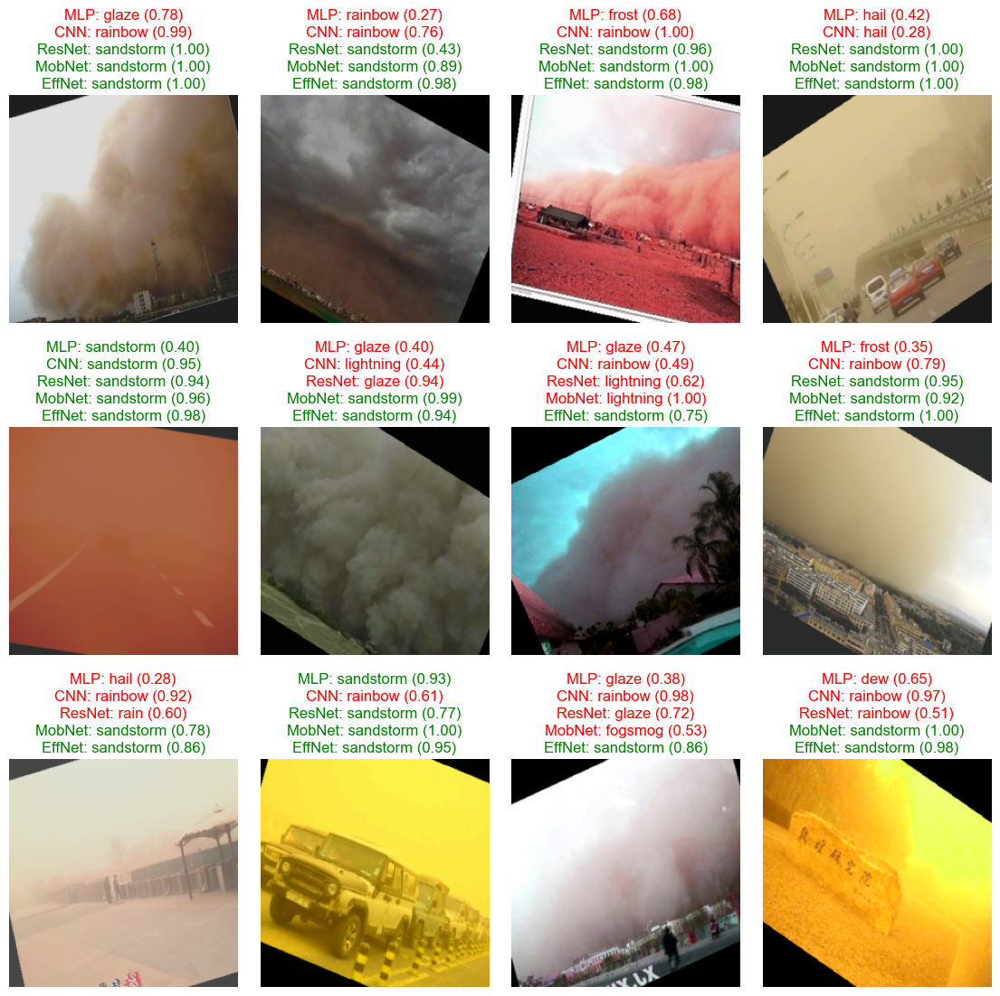

In [40]:
plot_preds("sandstorm", dataset=aug_dataset, indices_dict=aug_indices, all_preds=aug_preds)

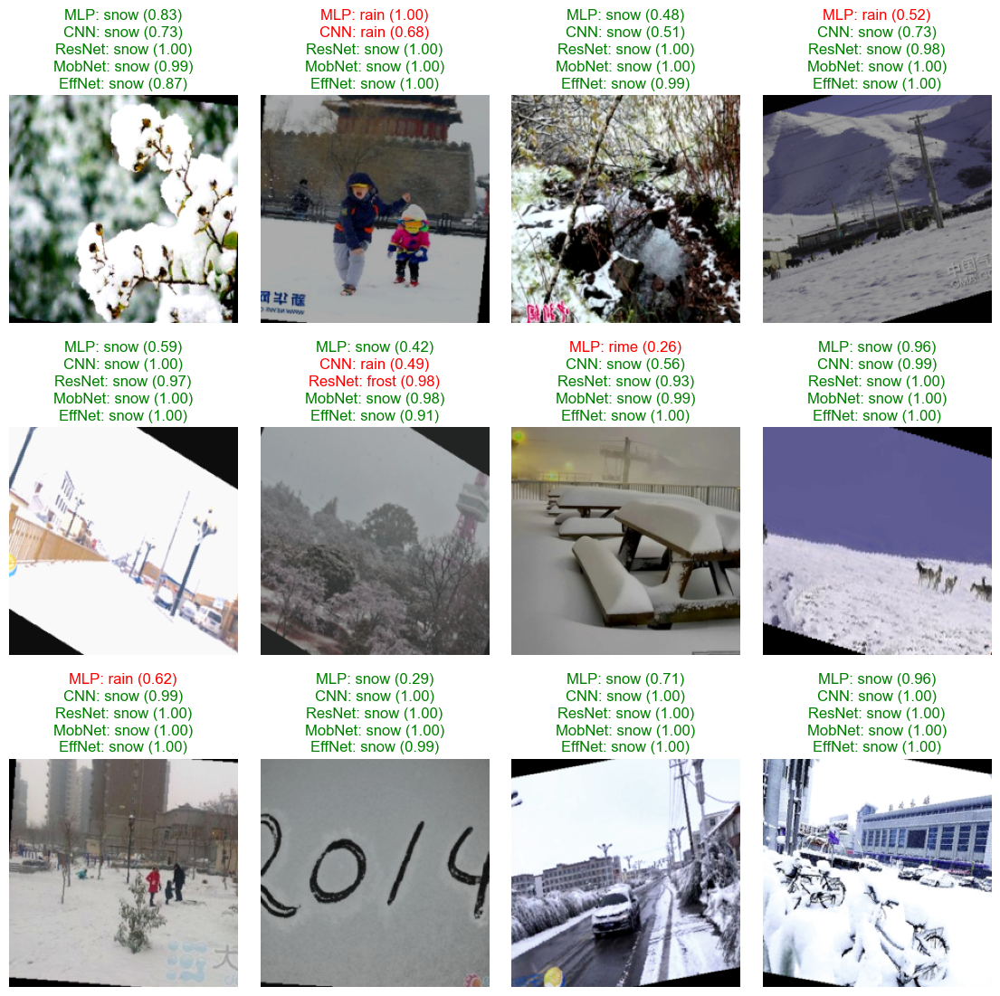

In [41]:
plot_preds("snow", dataset=aug_dataset, indices_dict=aug_indices, all_preds=aug_preds)

## Stable Diffusion

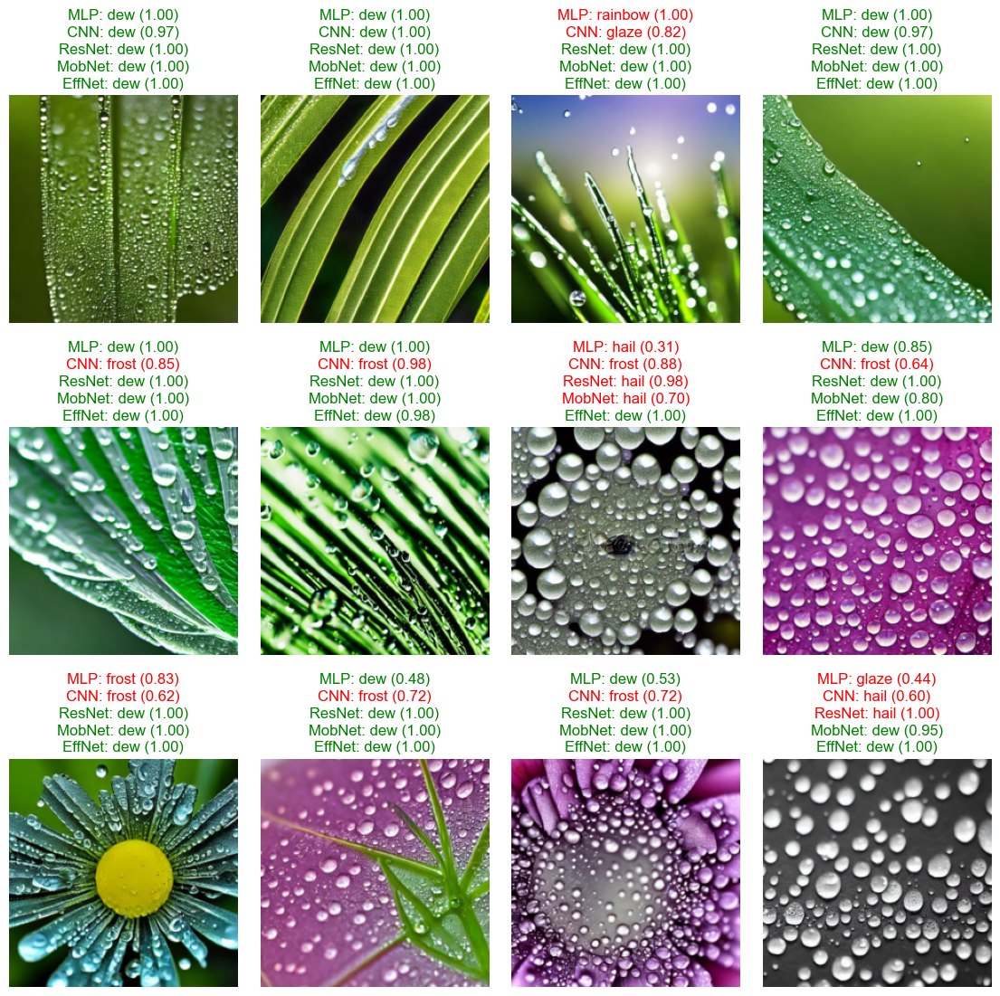

In [42]:
plot_preds("dew", dataset=diffusion_dataset, indices_dict=diffusion_indices, all_preds=diffusion_preds)

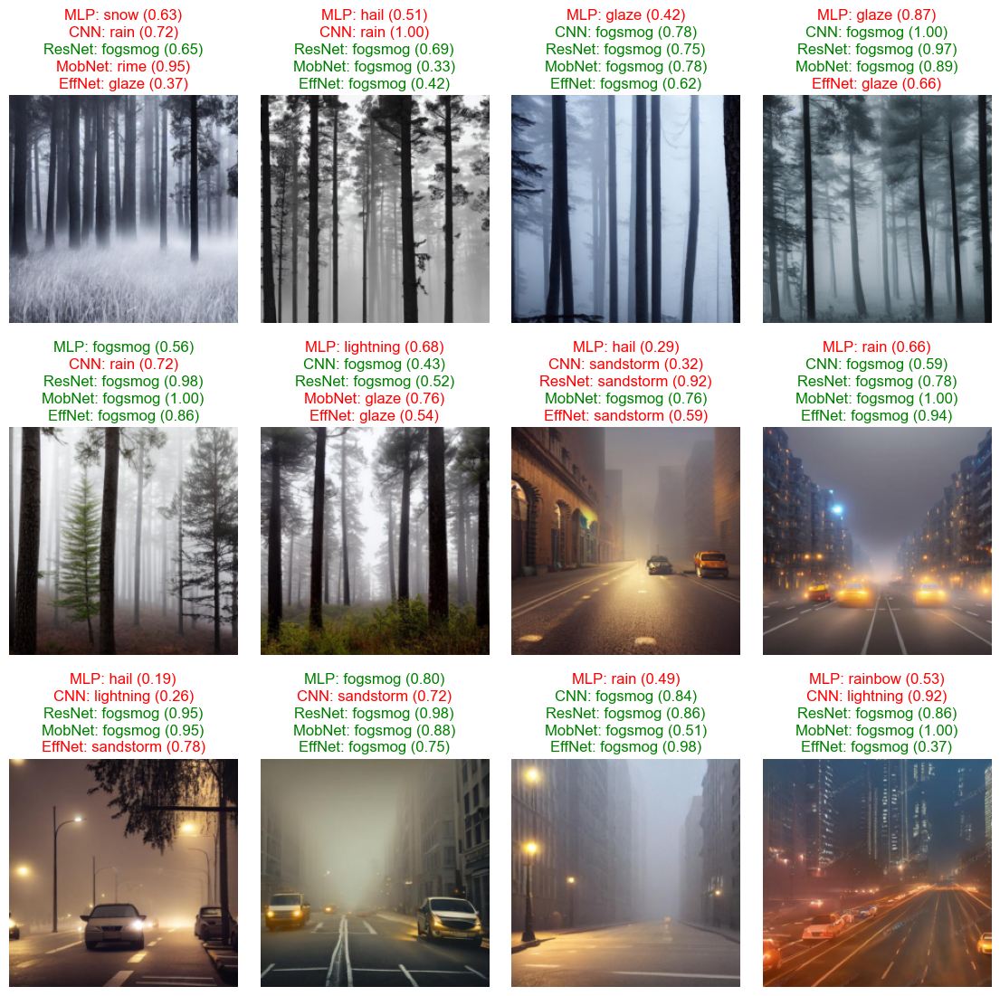

In [43]:
plot_preds("fogsmog", dataset=diffusion_dataset, indices_dict=diffusion_indices, all_preds=diffusion_preds)

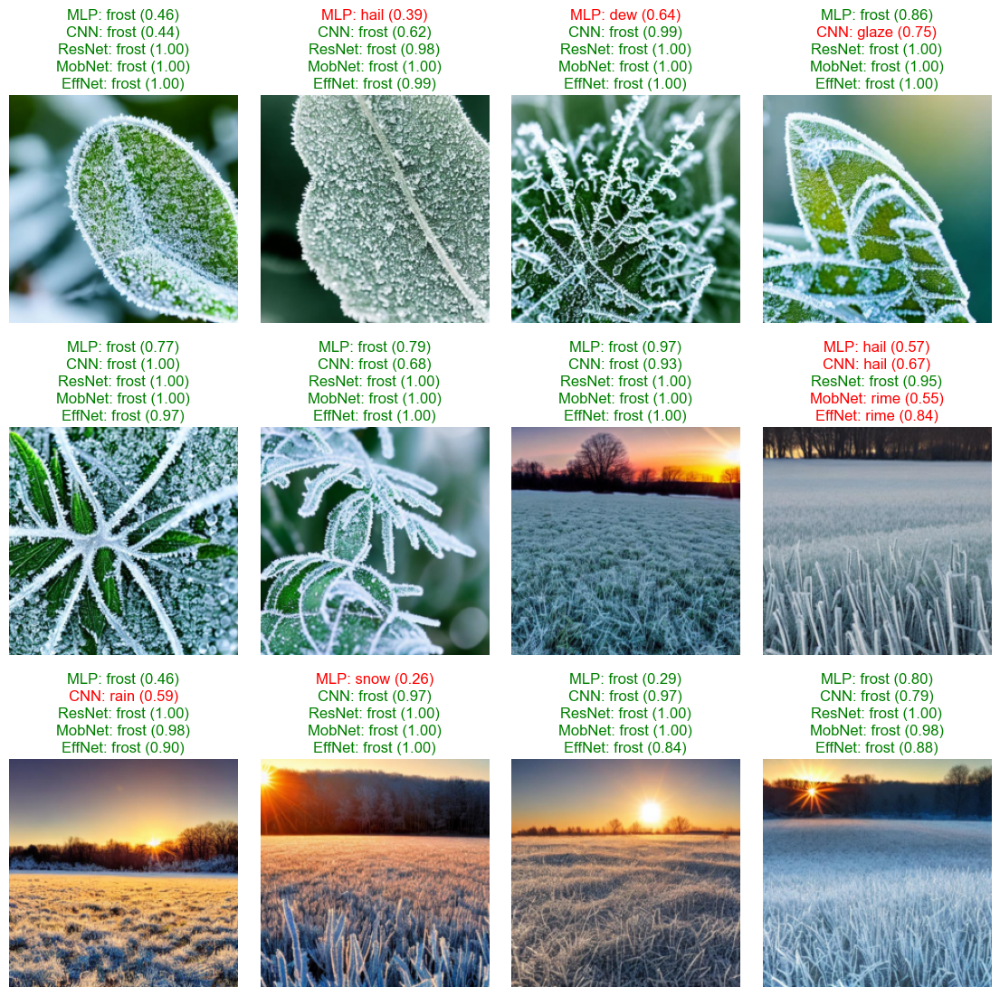

In [44]:
plot_preds("frost", dataset=diffusion_dataset, indices_dict=diffusion_indices, all_preds=diffusion_preds)

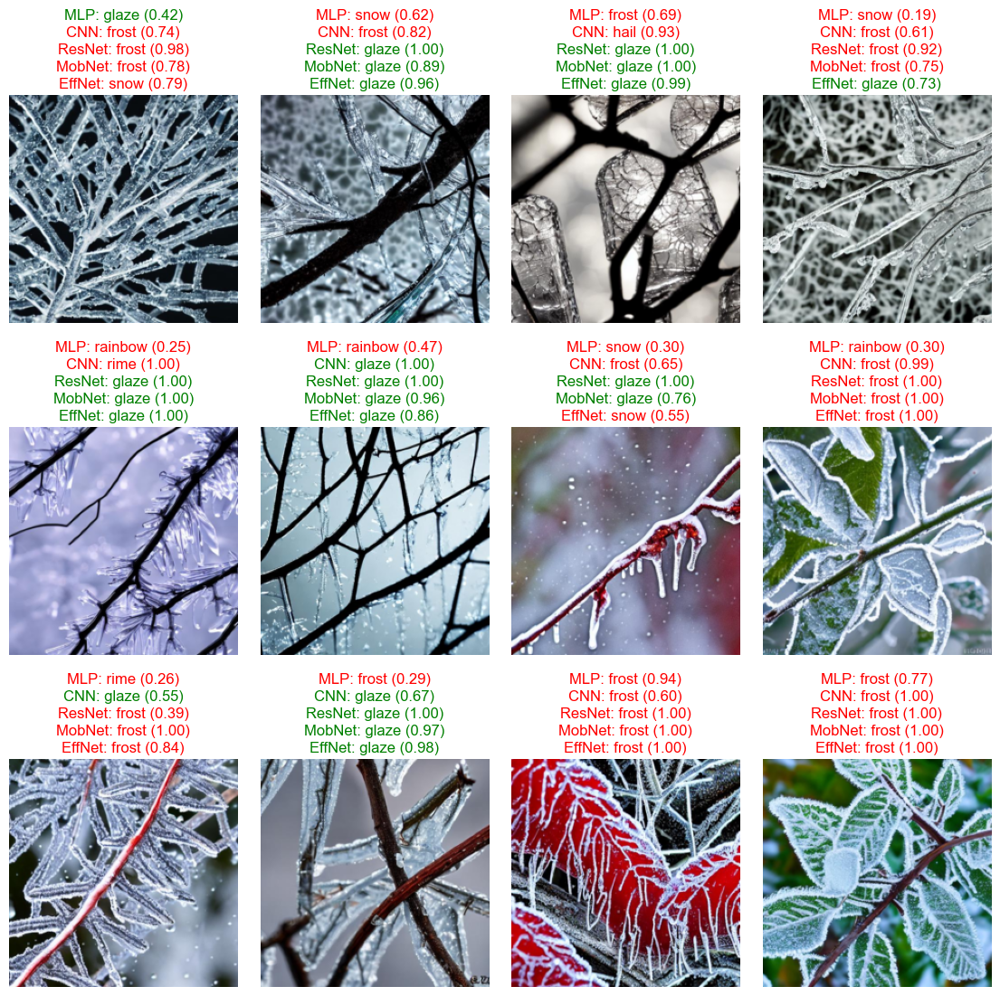

In [45]:
plot_preds("glaze", dataset=diffusion_dataset, indices_dict=diffusion_indices, all_preds=diffusion_preds)

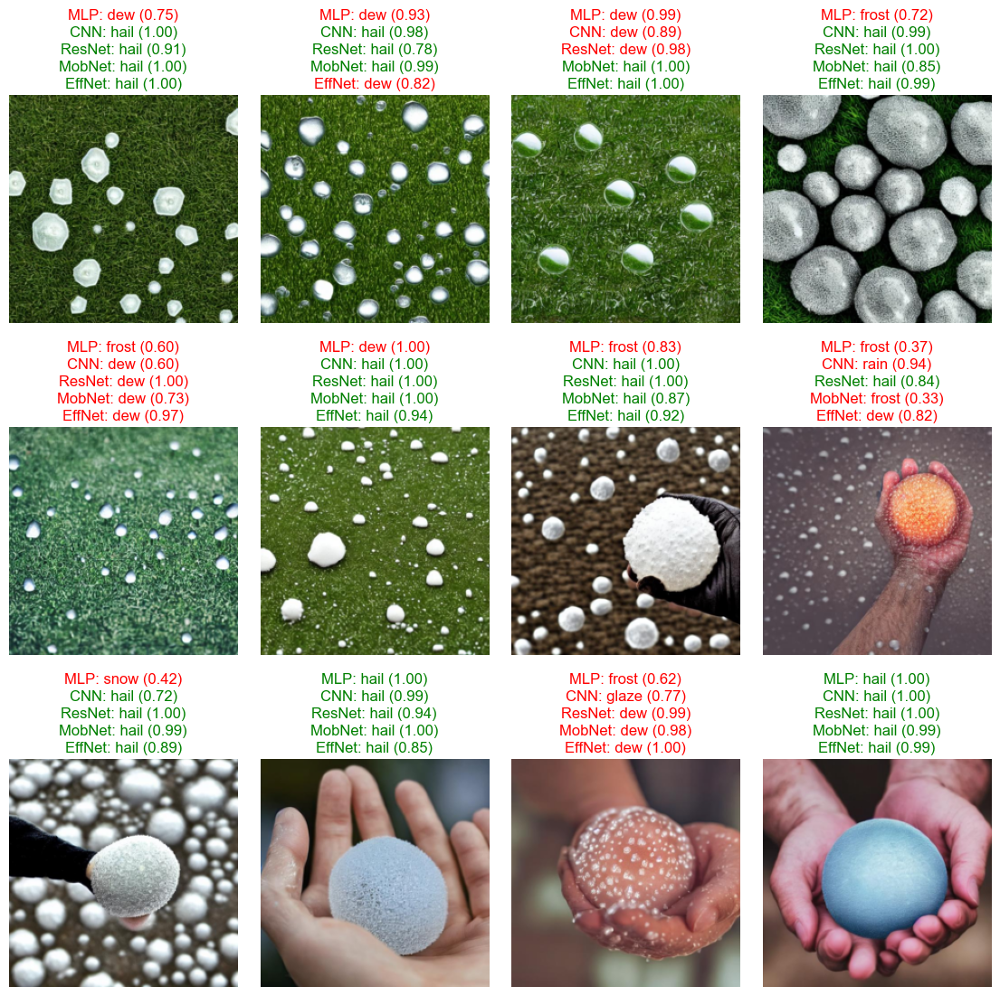

In [46]:
plot_preds("hail", dataset=diffusion_dataset, indices_dict=diffusion_indices, all_preds=diffusion_preds)

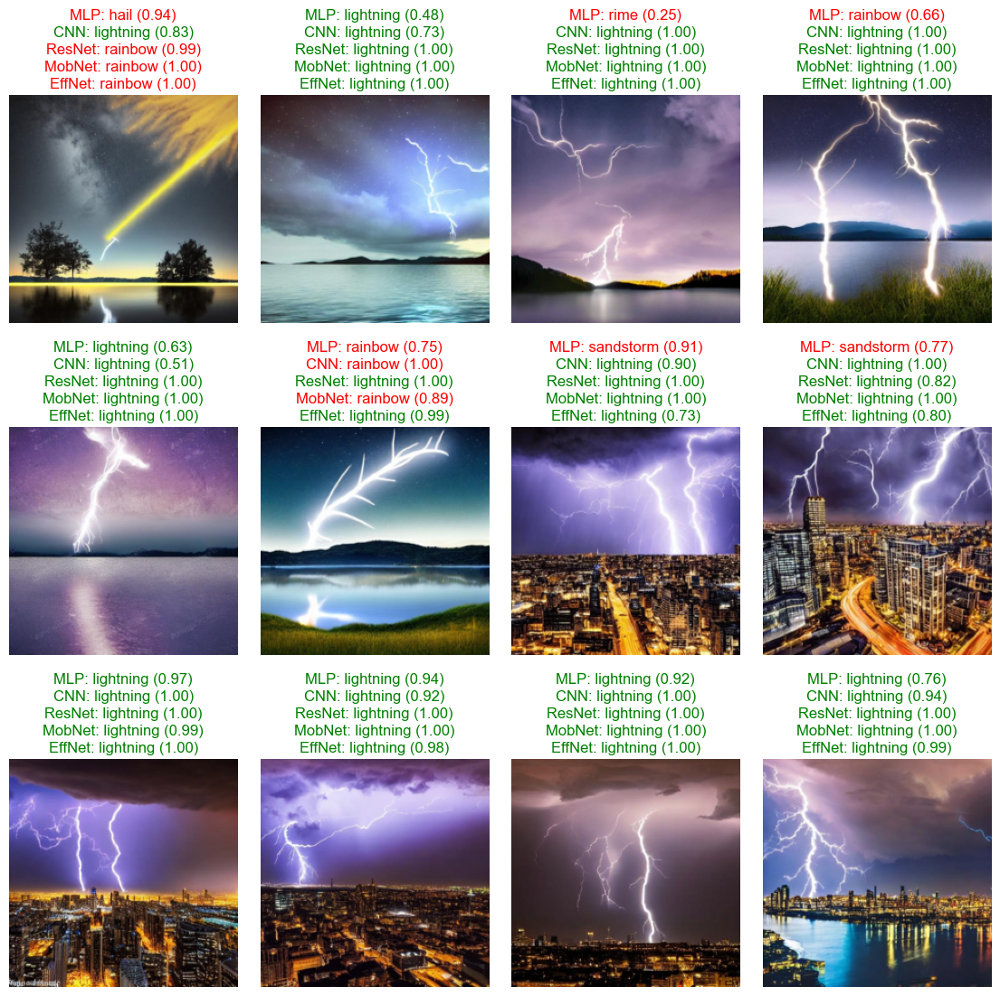

In [47]:
plot_preds("lightning", dataset=diffusion_dataset, indices_dict=diffusion_indices, all_preds=diffusion_preds)

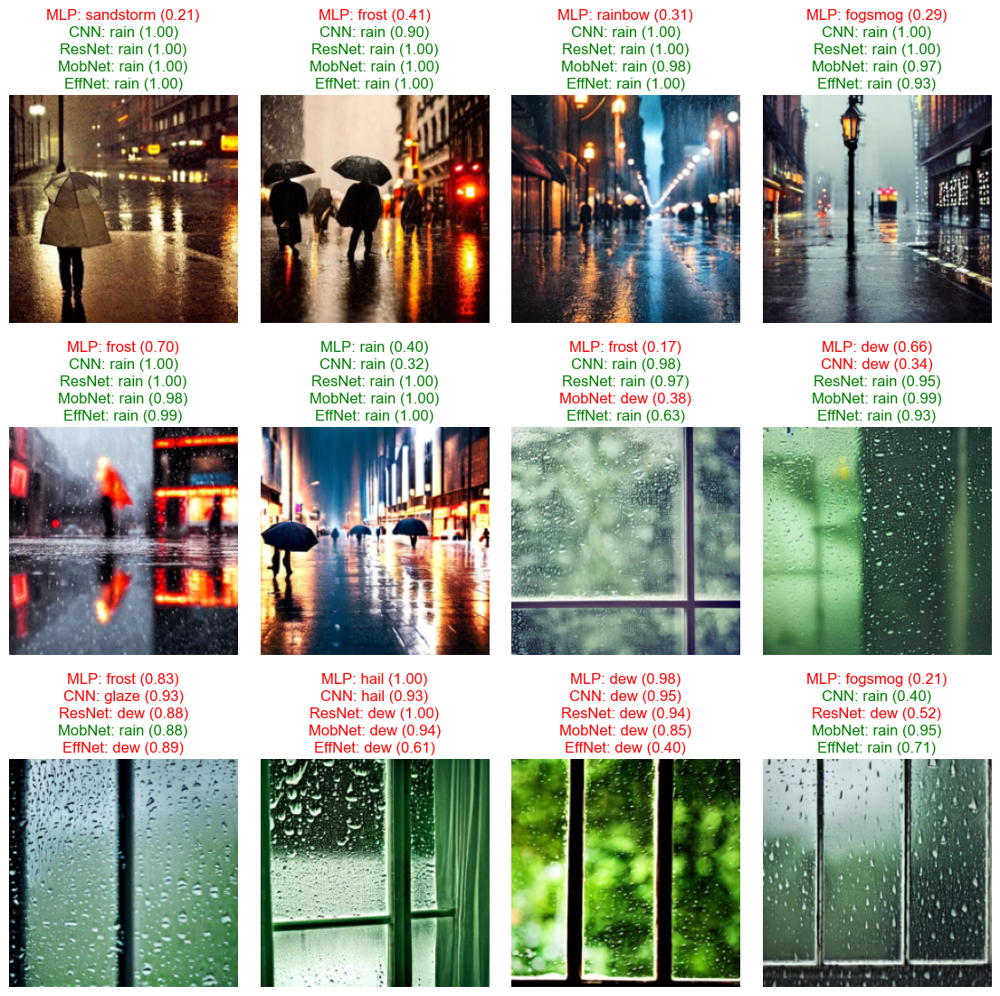

In [48]:
plot_preds("rain", dataset=diffusion_dataset, indices_dict=diffusion_indices, all_preds=diffusion_preds)

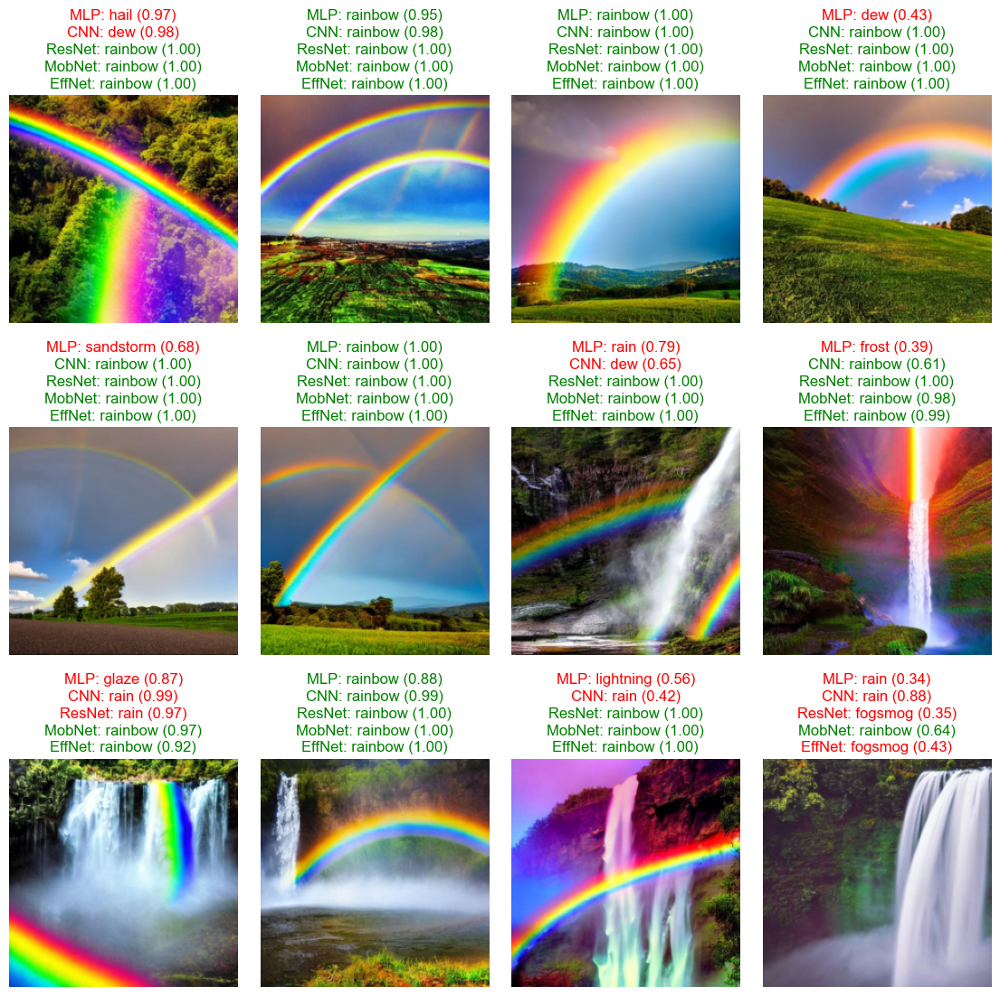

In [49]:
plot_preds("rainbow", dataset=diffusion_dataset, indices_dict=diffusion_indices, all_preds=diffusion_preds)

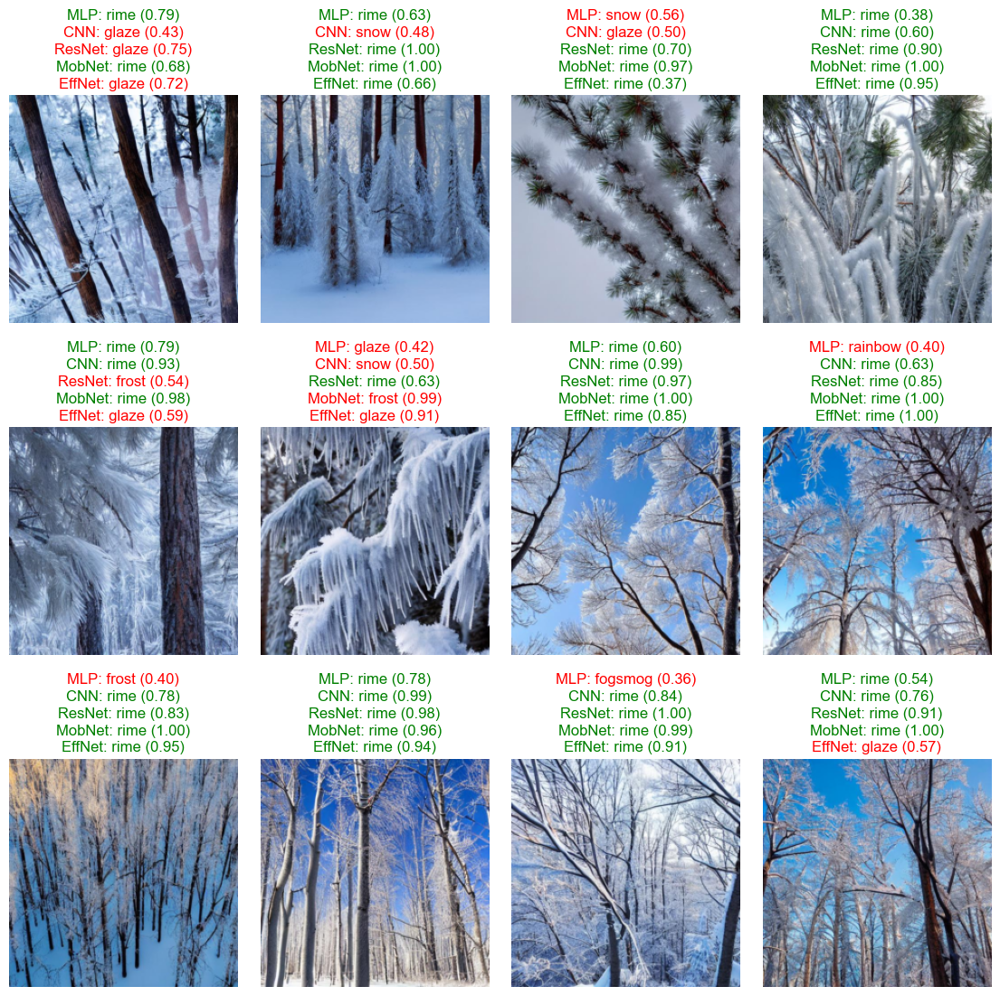

In [50]:
plot_preds("rime", dataset=diffusion_dataset, indices_dict=diffusion_indices, all_preds=diffusion_preds)

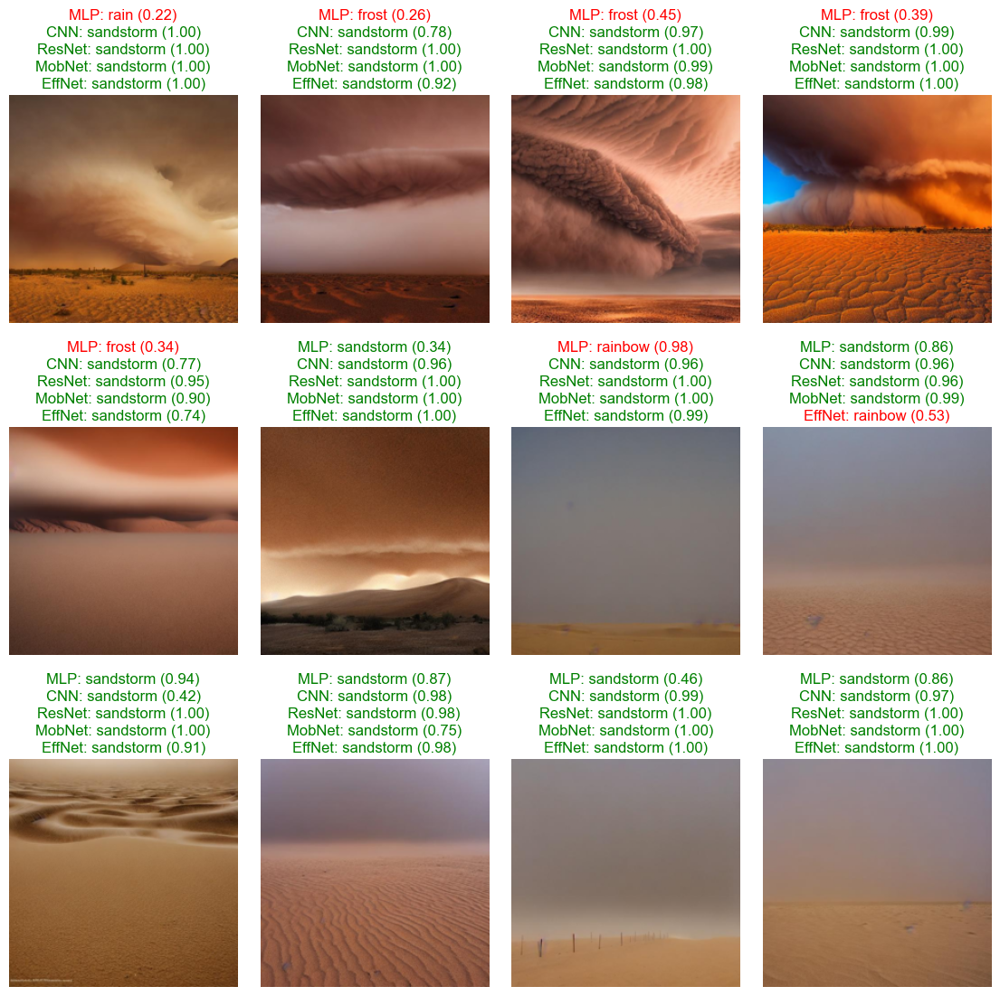

In [51]:
plot_preds("sandstorm", dataset=diffusion_dataset, indices_dict=diffusion_indices, all_preds=diffusion_preds)

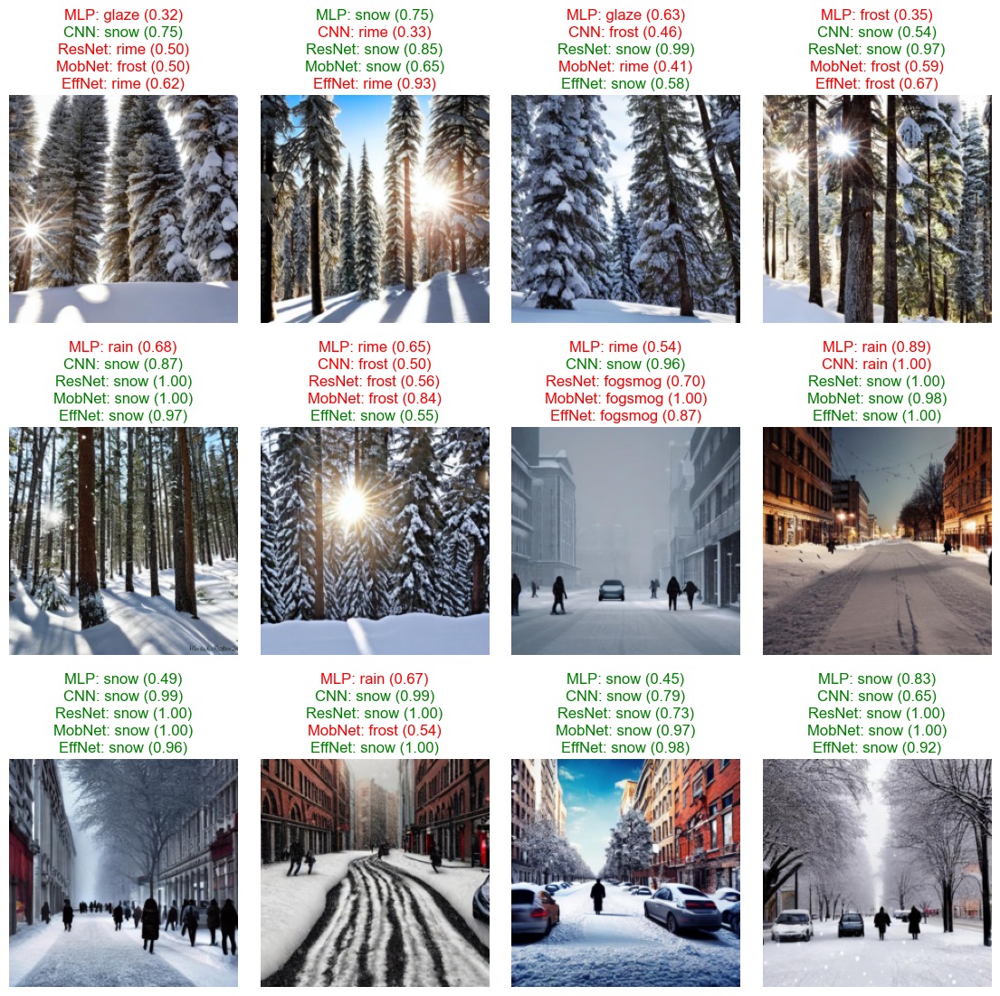

In [52]:
plot_preds("snow", dataset=diffusion_dataset, indices_dict=diffusion_indices, all_preds=diffusion_preds)

# Визуализация внутреннего внимания моделей

In [ ]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model

        for name, module in model.named_modules():
            if name == target_layer:
                self.target_layer = module
                break

        self.target_layer.register_forward_hook(self._forward_hook)
        self.target_layer.register_full_backward_hook(self._backward_hook)

        self.gradients = None
        self.activations = None

    def _forward_hook(self, module, input, output):
        self.activations = output.detach()

    def _backward_hook(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def __call__(self, x, label=None):
        self.model.eval()
        output = self.model(x)

        self.model.zero_grad()
        one_hot = torch.zeros_like(output)
        one_hot[0, label] = 1
        output.backward(gradient=one_hot, retain_graph=False)

        gradients = self.gradients[0]
        weights = torch.mean(gradients, dim=(1, 2))
        activations = self.activations[0]

        cam = torch.zeros(activations.shape[1:], dtype=torch.float32, device=activations.device)
        for i, w in enumerate(weights):
            cam += w * activations[i]

        cam = F.relu(cam)
        cam = cam - cam.min()
        if cam.max() != 0:
            cam = cam / cam.max()
        else:
            cam = cam * 0

        cam = cam.unsqueeze(0).unsqueeze(0)
        cam = F.interpolate(cam, size=x.shape[2:], mode='bilinear', align_corners=False)
        cam = cam.squeeze().cpu().numpy()

        return cam


def get_target_layers():
    layers_names = {}
    for model_name, model in models_dict.items():
        if model_name.startswith("Weather"):
            continue
        last_conv_name = None
        for name, module in model.named_modules():
            if isinstance(module, torch.nn.Conv2d):
                last_conv_name = name
        layers_names[model_name] = last_conv_name
    return layers_names


def plot_gradcams(dataset, indices):
    n_cols = 4
    n_rows = len(indices)

    _, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(14, n_rows * 4))

    models_order = ["ResNet18", "MobileNetV3-Large", "EfficientNet-B0"]

    for i, image_index in enumerate(indices):
        image_tensor, target = dataset[image_index]
        H, W = image_tensor.shape[1], image_tensor.shape[2]

        image_array = image_tensor.cpu().numpy().transpose(1, 2, 0)
        image_array = image_array * std + mean
        image_array = np.clip(image_array, 0, 1)

        ax = axes[i, 0]
        ax.imshow(image_array)
        ax.axis("off")
        ax.set_title(class_names[target], color="black")

        for j, model_name in enumerate(models_order):
            model = models_dict[model_name]
            model.eval()
            gradcam = GradCAM(model, target_layers[model_name])

            input_batch = image_tensor.unsqueeze(0).to(current_device)

            with torch.no_grad():
                logits = model(input_batch)
                probs = torch.softmax(logits, dim=1)
                prob, pred = probs.max(dim=1)
                prob = prob.item()
                pred = pred.item()

            cam = gradcam(input_batch, label=pred)

            cam_resized = cv2.resize(cam, (W, H))
            heatmap = cv2.applyColorMap(np.uint8(255 * cam_resized), cv2.COLORMAP_JET)
            heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
            overlay = 0.5 * image_array + 0.5 * heatmap / 255.0
            overlay = np.clip(overlay, 0, 1)

            ax = axes[i, j + 1]
            ax.imshow(overlay)
            ax.axis("off")
            ax.set_title(
                f"{models_short[model_name]}: {class_names[pred]} ({prob:.2f})",
                color="green" if pred == target else "red"
            )

    plt.subplots_adjust(wspace=0.1, hspace=0.2)


def select_indices(indices_dict):
    selected = []
    for _, indices in indices_dict.items():
        selected.extend([indices[0], indices[n_images_per_class // 2]])
    return selected

photos_selected = select_indices(photos_indices)
aug_selected = select_indices(aug_indices)
diffusion_selected = select_indices(diffusion_indices)

(target_layers := get_target_layers())

{'ResNet18': 'layer4.1.conv2',
 'MobileNetV3-Large': 'features.16.0',
 'EfficientNet-B0': 'features.8.0'}

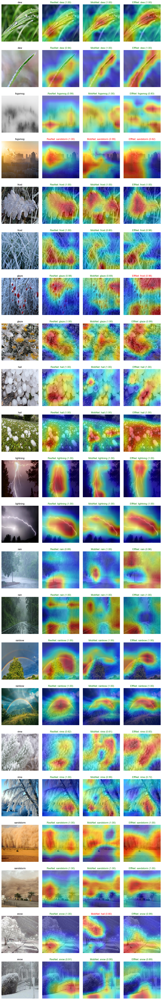

In [54]:
plot_gradcams(photos_dataset, photos_selected)

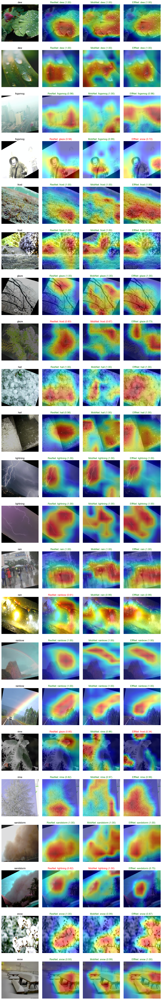

In [55]:
plot_gradcams(aug_dataset, aug_selected)

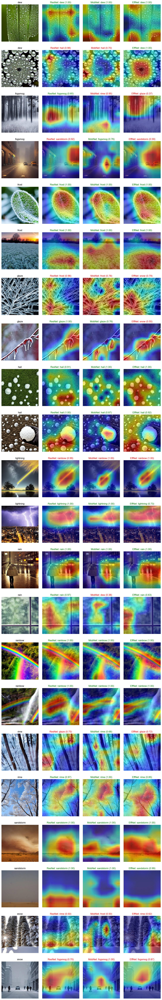

In [56]:
plot_gradcams(diffusion_dataset, diffusion_selected)